# **Modelo de Machine Learning de los factores de Detracción en el Campus Cusco**

Este cuaderno amplía `NPS2025ACAD_CUSCO.ipynb`. Allí se ajustó una Regresión Logística por bloque de
preguntas; aquí se comparan varios modelos de Machine Learning con validación cruzada estratificada,
se elige el mejor por bloque y se explica qué factores pesan más en que un estudiante del campus Cusco
sea **DETRACTOR** (DETRACTOR = 1).

Bloques analizados (los mismos de `NPS2025ACAD_CUSCO.ipynb`):
1. Satisfacción general por dimensión (SATIF_ACAD, SATISF_SERV, ...).
2. P4: subcomponentes de la satisfacción académica.
3. P26: comunicación e imagen de la universidad.

Funciona en Google Colab (lee `DATANPS2025.csv` y `utilidadesML.py` de `MyDrive/Colab Notebooks`)
y también en local (los busca en la carpeta del script o del cuaderno).

# **Importar paquetes**

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, accuracy_score, confusion_matrix,
                             roc_auc_score, RocCurveDisplay)

warnings.filterwarnings('ignore')
SEMILLA = 42

# **Preparación del acceso al Drive**

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA_DATOS = '/content/drive/MyDrive/Colab Notebooks'
except ImportError:
    # Ejecución local: los archivos están junto al script / cuaderno
    RUTA_DATOS = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()

# Agregar la carpeta de utilidadesML al path de Python
sys.path.append(RUTA_DATOS)

import utilidadesML as ml

# **Lectura de los datos**

In [3]:
estudiantes = pd.read_csv(os.path.join(RUTA_DATOS, 'DATANPS2025.csv'), sep=";")

# **Filtrado del Campus Cusco**

In [4]:
estudiantes_CUSCO = estudiantes[estudiantes['X_CAMPUS'] == 'CZC'].copy()
print(f"Estudiantes del campus Cusco: {len(estudiantes_CUSCO)}")
print(estudiantes_CUSCO['DETRACTOR'].value_counts().rename({0: 'No detractor', 1: 'Detractor'}))
print(f"Proporción de detractores: {estudiantes_CUSCO['DETRACTOR'].mean():.1%}")

Estudiantes del campus Cusco: 1794
DETRACTOR
No detractor    1462
Detractor        332
Name: count, dtype: int64
Proporción de detractores: 18.5%


**Las clases están desbalanceadas (≈ 1 detractor por cada 4 no detractores).** Por eso:
- se usa `class_weight='balanced'` en los modelos que lo permiten,
- la partición entrenamiento/prueba es **estratificada**,
- además de la exactitud (accuracy) se miran **ROC-AUC**, **recall** y **F1 de la clase detractor**,
  que son las métricas que importan cuando queremos encontrar a los detractores.

# **Funciones del análisis**

Se definen una sola vez y se aplican a cada bloque de preguntas.

In [5]:
def candidatos_modelo():
    """Modelos a comparar. Todos manejan el desbalance de clases."""
    return {
        'Regresión Logística': make_pipeline(
            StandardScaler(),
            LogisticRegression(solver='liblinear', max_iter=500, random_state=50, class_weight='balanced')),
        'Random Forest': RandomForestClassifier(
            n_estimators=300, max_depth=6, min_samples_leaf=5, random_state=SEMILLA,
            class_weight='balanced', n_jobs=-1),
        'Gradient Boosting': HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEMILLA,
            class_weight='balanced'),
    }


def refinar_variables(data, columnas, titulo_bloque):
    """Pruebas t de diferencia de medias (utilidadesML) para quedarnos con las variables significativas."""
    X = data[columnas]
    XCopia = X.copy()
    for column in X.columns:
        title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
        ml.analisis_variable_violin(data, "DETRACTOR", column, title)
        ml.prueba_t(data, 'DETRACTOR', column, 1, 0, XCopia)
    print(f"[{titulo_bloque}] Variables que pasan la prueba t: {list(XCopia.columns)}")
    return XCopia


def comparar_modelos(X_train, y_train):
    """Validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento."""
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    filas = []
    for nombre, modelo in candidatos_modelo().items():
        res = cross_validate(modelo, X_train, y_train, cv=cv,
                             scoring=['roc_auc', 'recall', 'f1', 'accuracy'])
        filas.append({'Modelo': nombre,
                      'ROC-AUC': res['test_roc_auc'].mean(),
                      'Recall detractor': res['test_recall'].mean(),
                      'F1 detractor': res['test_f1'].mean(),
                      'Accuracy': res['test_accuracy'].mean()})
    tabla = pd.DataFrame(filas).set_index('Modelo').sort_values('ROC-AUC', ascending=False)
    print(tabla.round(3))
    return tabla


def evaluar_modelo(modelo, nombre, X_test, y_test):
    """Matriz de confusión, reporte de clasificación y curva ROC en el conjunto de prueba."""
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]
    print(f'Modelo elegido: {nombre}')
    print(f'Accuracy en prueba: {accuracy_score(y_test, y_pred):.3f}')
    print(f'ROC-AUC en prueba: {roc_auc_score(y_test, y_prob):.3f}')
    print(f'Reporte de clasificación:\n{classification_report(y_test, y_pred)}')

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0])
    axes[0].set_title(f'Matriz de Confusión - {nombre}')
    axes[0].set_xlabel('Predicción')
    axes[0].set_ylabel('Valor Real')
    RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name=nombre)
    axes[1].plot([0, 1], [0, 1], linestyle='--', color='grey')
    axes[1].set_title('Curva ROC')
    plt.tight_layout()
    plt.show()


def importancia_variables(modelo, nombre, X_test, y_test):
    """Importancia por permutación: cuánto cae el ROC-AUC al desordenar cada variable."""
    imp = permutation_importance(modelo, X_test, y_test, scoring='roc_auc',
                                 n_repeats=20, random_state=SEMILLA, n_jobs=-1)
    importancias = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
    print(importancias.sort_values(ascending=False).round(4))

    plt.figure(figsize=(10, max(4, 0.45 * len(importancias))))
    bars = plt.barh(importancias.index, importancias.values)
    for bar in bars:
        plt.annotate(f'{bar.get_width():.3f}', xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                     xytext=(3, 0), textcoords="offset points", va='center', fontsize=8)
    plt.xlabel('Caída media del ROC-AUC')
    plt.title(f'Importancia por permutación - {nombre}')
    plt.tight_layout()
    plt.show()
    return importancias.sort_values(ascending=False)


def analisis_shap(modelo, nombre, X_train, X_test):
    """Valores SHAP sobre la probabilidad de ser detractor."""
    import shap
    fondo = shap.kmeans(X_train, 50)
    muestra = X_test.sample(min(200, len(X_test)), random_state=SEMILLA)
    explainer = shap.KernelExplainer(lambda d: modelo.predict_proba(d)[:, 1], fondo)
    shap_values = explainer.shap_values(muestra, silent=True)

    plt.title(f'Importancia de las Características (SHAP) - {nombre}')
    shap.summary_plot(shap_values, muestra, feature_names=muestra.columns, plot_type="bar")
    plt.title(f'Importancia de las Características (SHAP) - {nombre}')
    shap.summary_plot(shap_values, muestra, feature_names=muestra.columns)


def modelar_bloque(data, columnas, titulo_bloque):
    """Flujo completo de un bloque: prueba t -> comparación -> evaluación -> explicación."""
    XCopia = refinar_variables(data, columnas, titulo_bloque)
    y = data['DETRACTOR']
    X_train, X_test, y_train, y_test = train_test_split(
        XCopia, y, test_size=0.20, random_state=SEMILLA, stratify=y)

    tabla = comparar_modelos(X_train, y_train)
    nombre = tabla.index[0]
    modelo = candidatos_modelo()[nombre].fit(X_train, y_train)

    evaluar_modelo(modelo, nombre, X_test, y_test)
    importancias = importancia_variables(modelo, nombre, X_test, y_test)
    analisis_shap(modelo, nombre, X_train, X_test)
    return {'tabla': tabla, 'modelo': nombre, 'importancias': importancias}


def matriz_correlacion(data, columnas, tam):
    plt.figure(figsize=(tam, tam))
    sns.heatmap(data[['DETRACTOR'] + columnas].corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Matriz de Correlación')
    plt.show()


resultados = {}

# **1. Satisfacción general por dimensión**

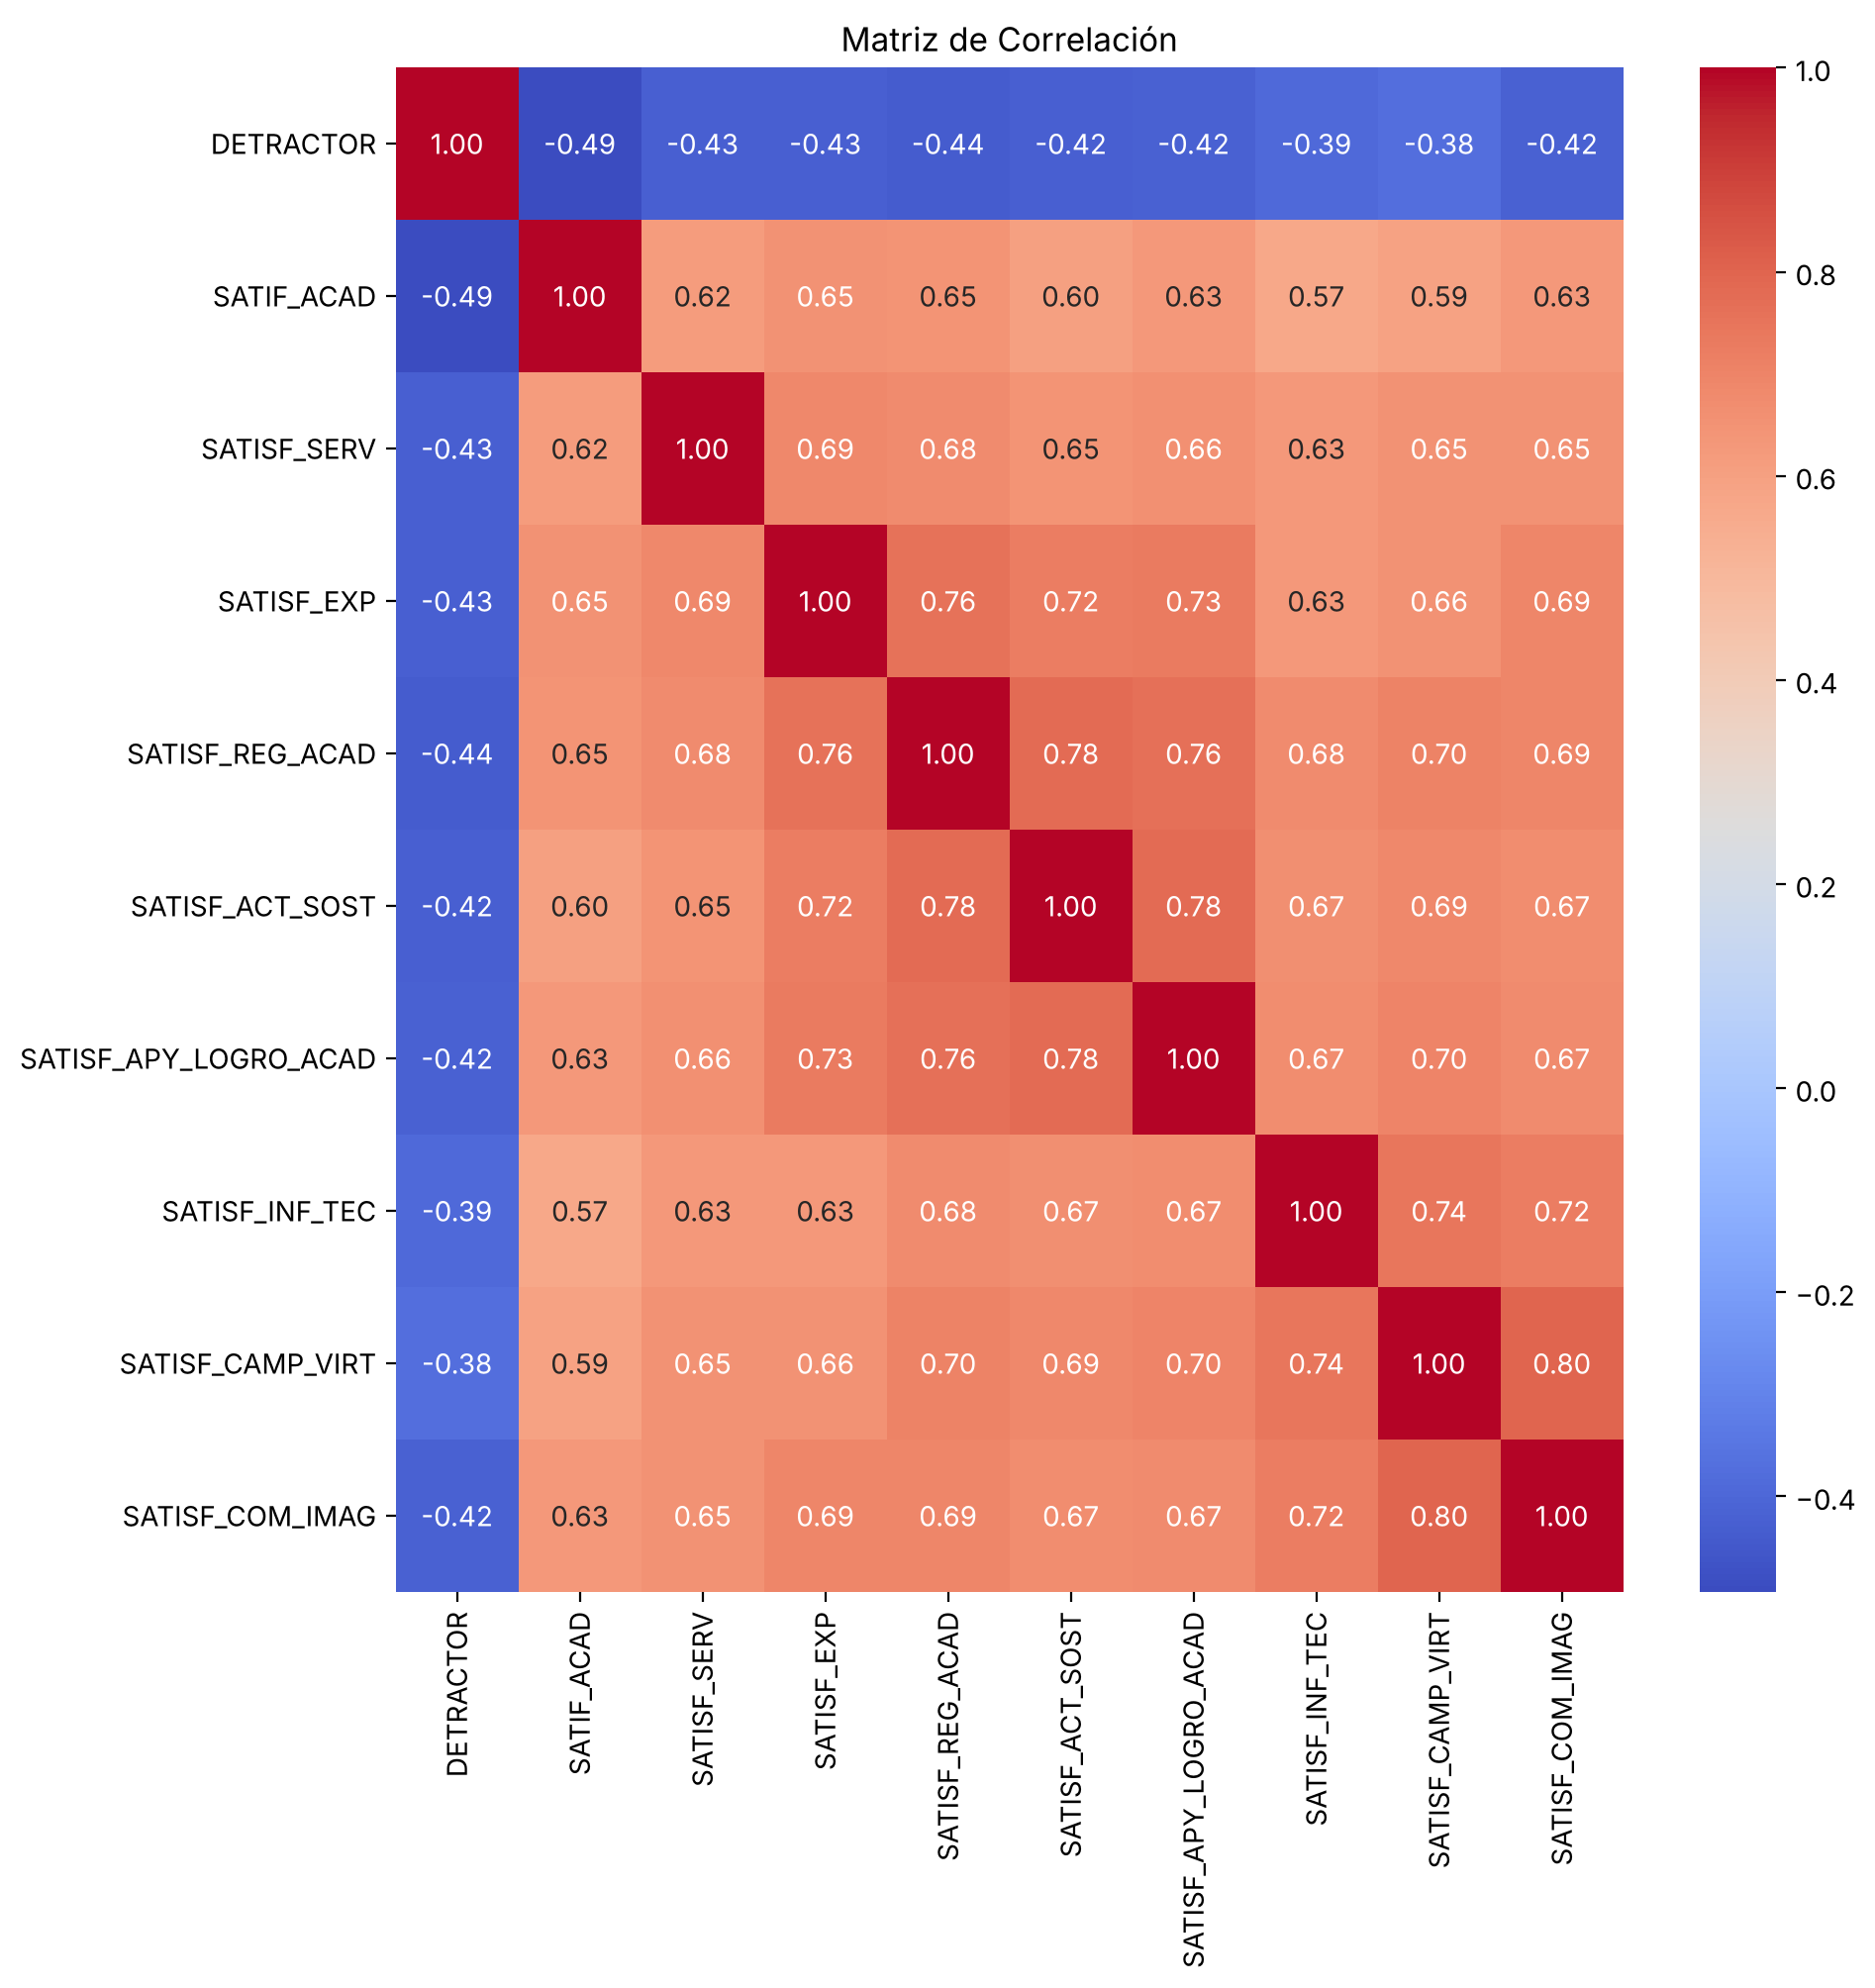

In [6]:
cols_general = ['SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST',
                'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']
matriz_correlacion(estudiantes_CUSCO, cols_general, 10)

**Pruebas t, comparación de modelos, evaluación e importancia de variables**

En el gráfico SHAP de calor: **si ves puntos rojos en el lado izquierdo y azules en el derecho, valores
altos de la característica disminuyen la probabilidad de ser detractor y valores bajos la aumentan.**

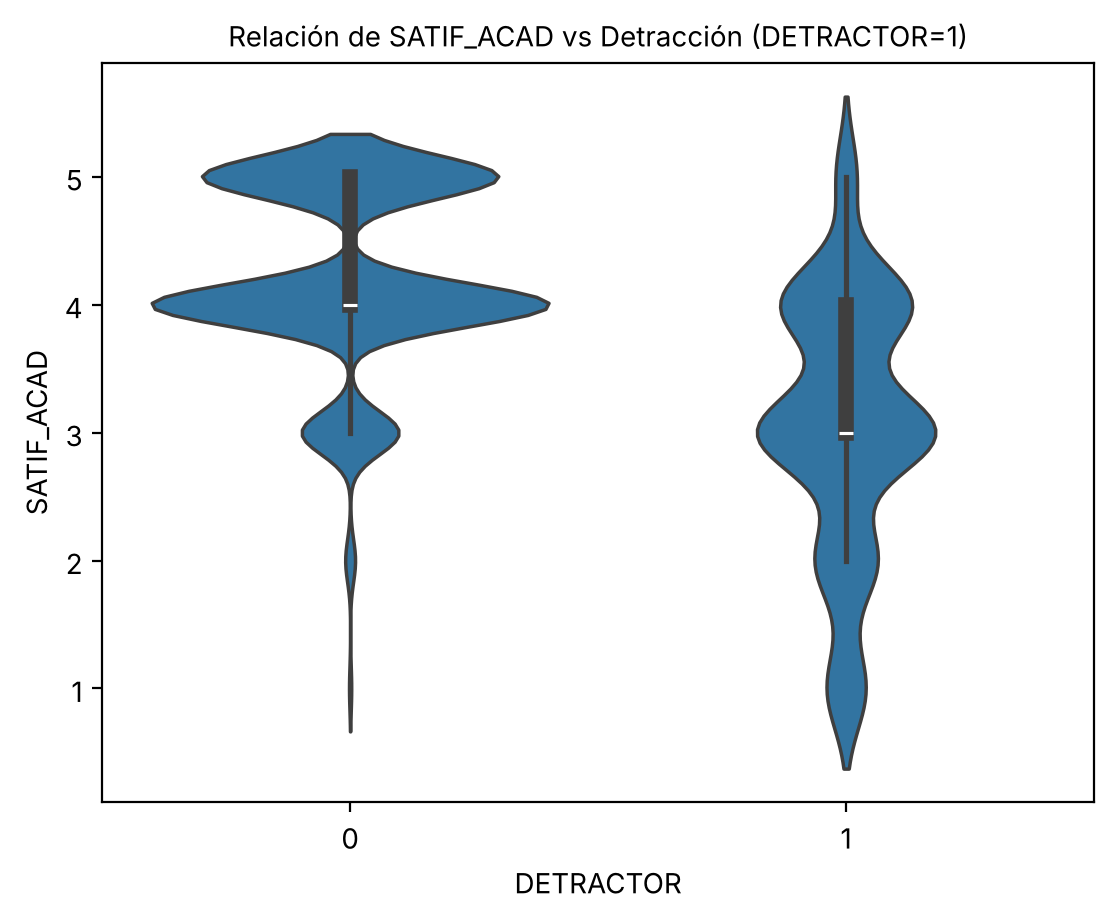

*** Prueba t para SATIF_ACAD ***
Estadístico t: -24.05771
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.214774
1    3.075301
Name: SATIF_ACAD, dtype: float64




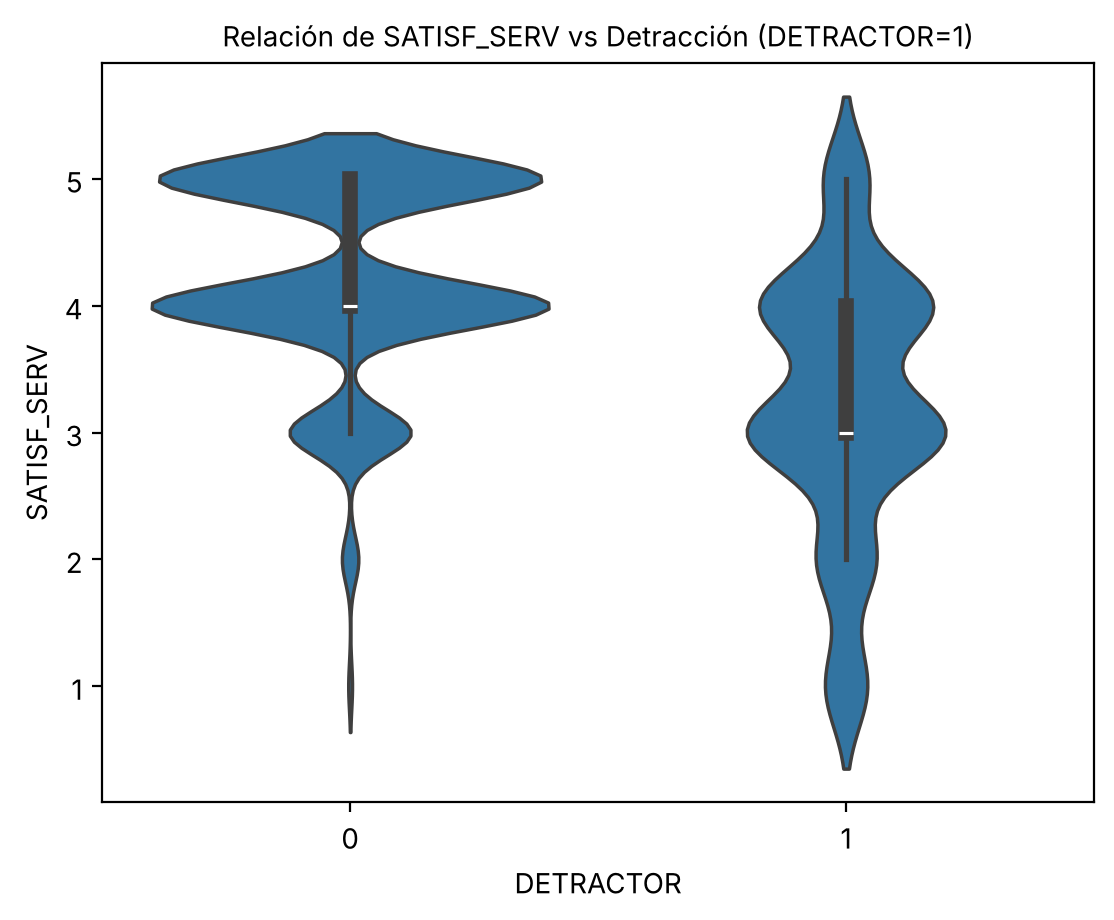

*** Prueba t para SATISF_SERV ***
Estadístico t: -19.92851
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.235978
1    3.231928
Name: SATISF_SERV, dtype: float64




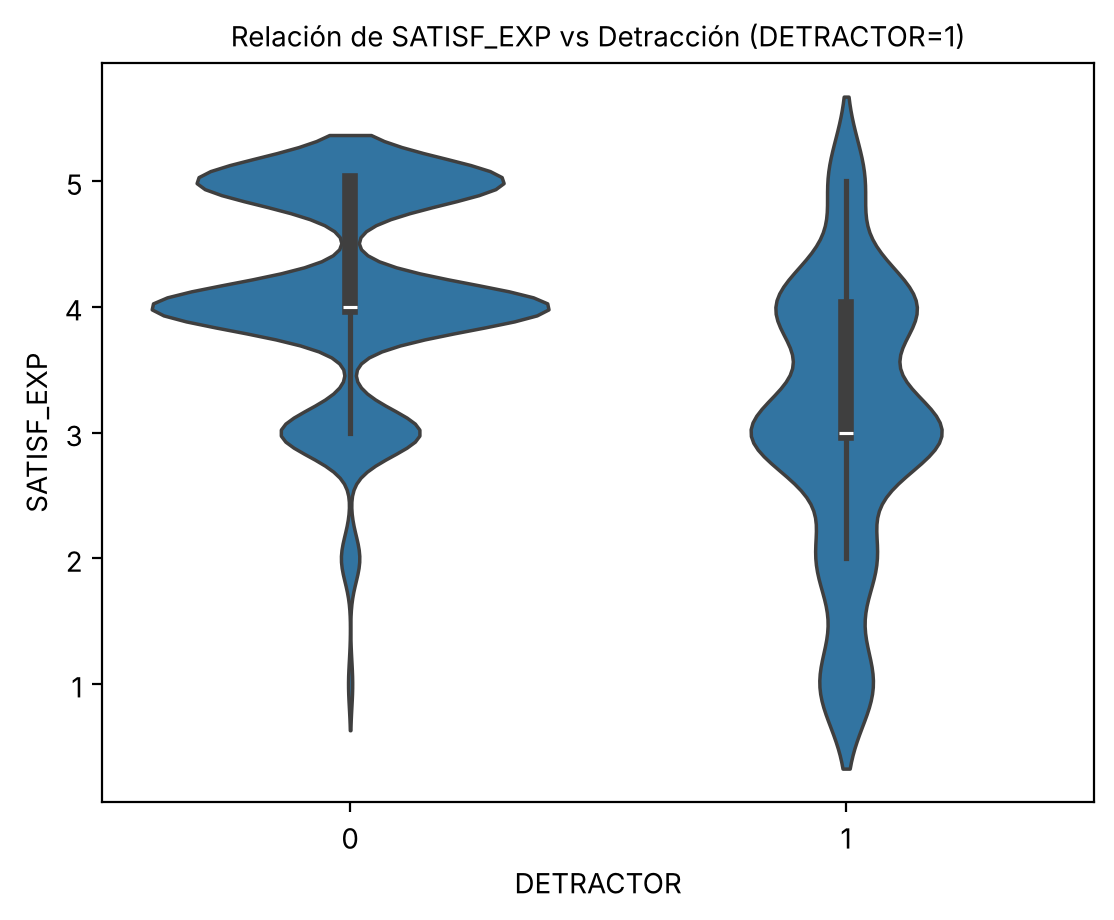

*** Prueba t para SATISF_EXP ***
Estadístico t: -20.12697
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.136799
1    3.096386
Name: SATISF_EXP, dtype: float64




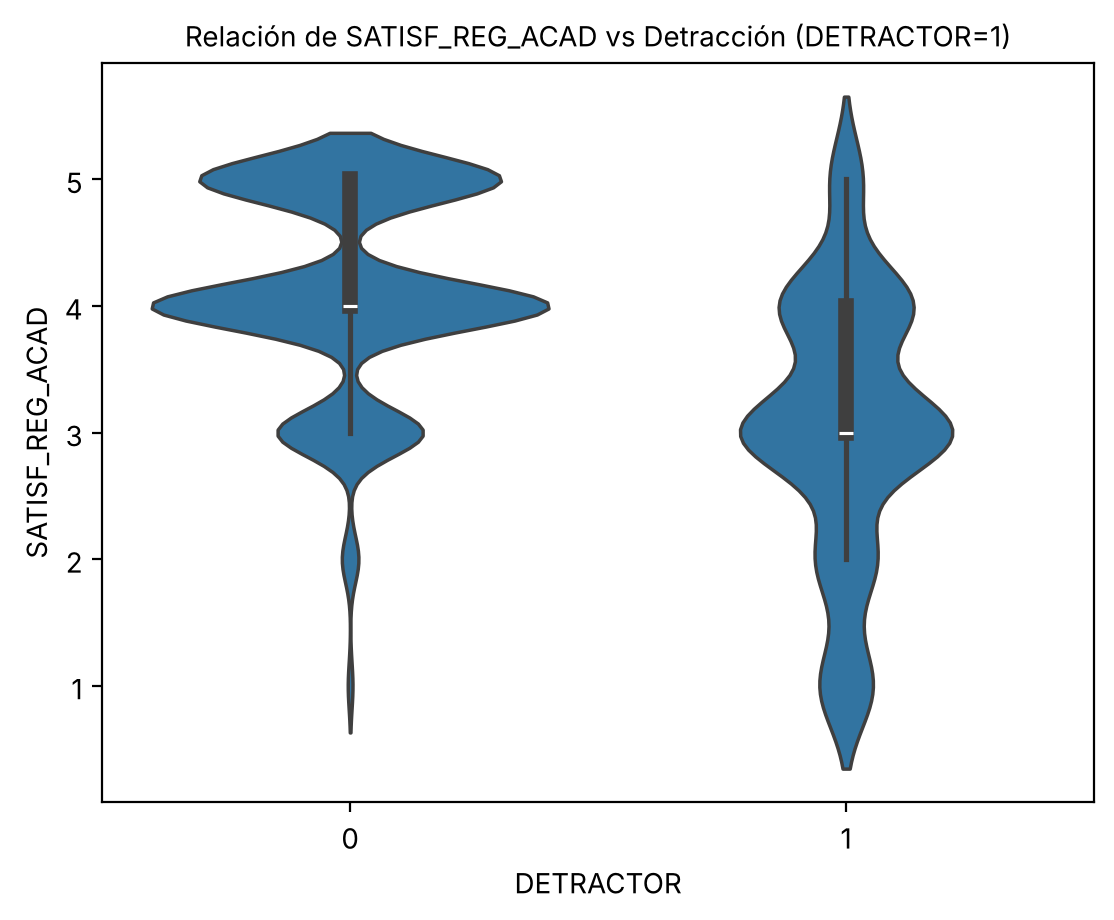

*** Prueba t para SATISF_REG_ACAD ***
Estadístico t: -20.68550
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.125171
1    3.063253
Name: SATISF_REG_ACAD, dtype: float64




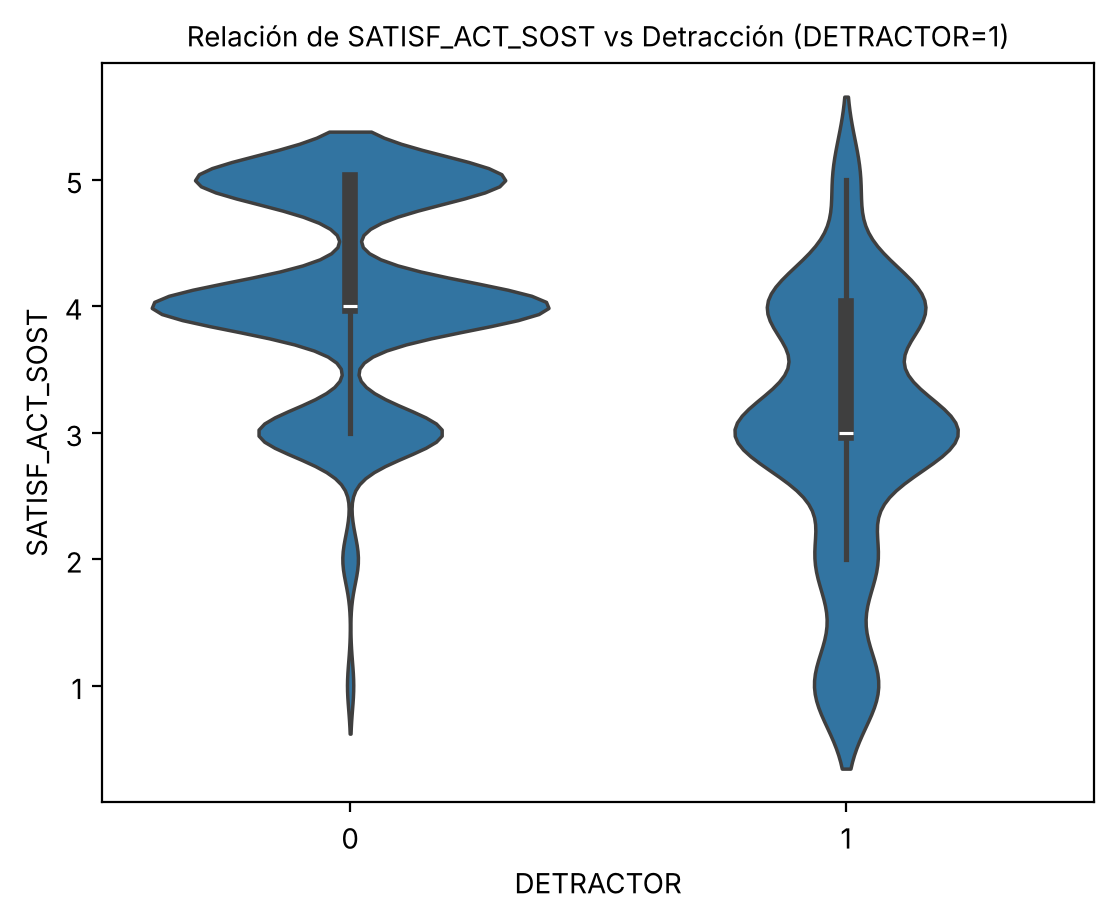

*** Prueba t para SATISF_ACT_SOST ***
Estadístico t: -19.83535
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.082763
1    3.042169
Name: SATISF_ACT_SOST, dtype: float64




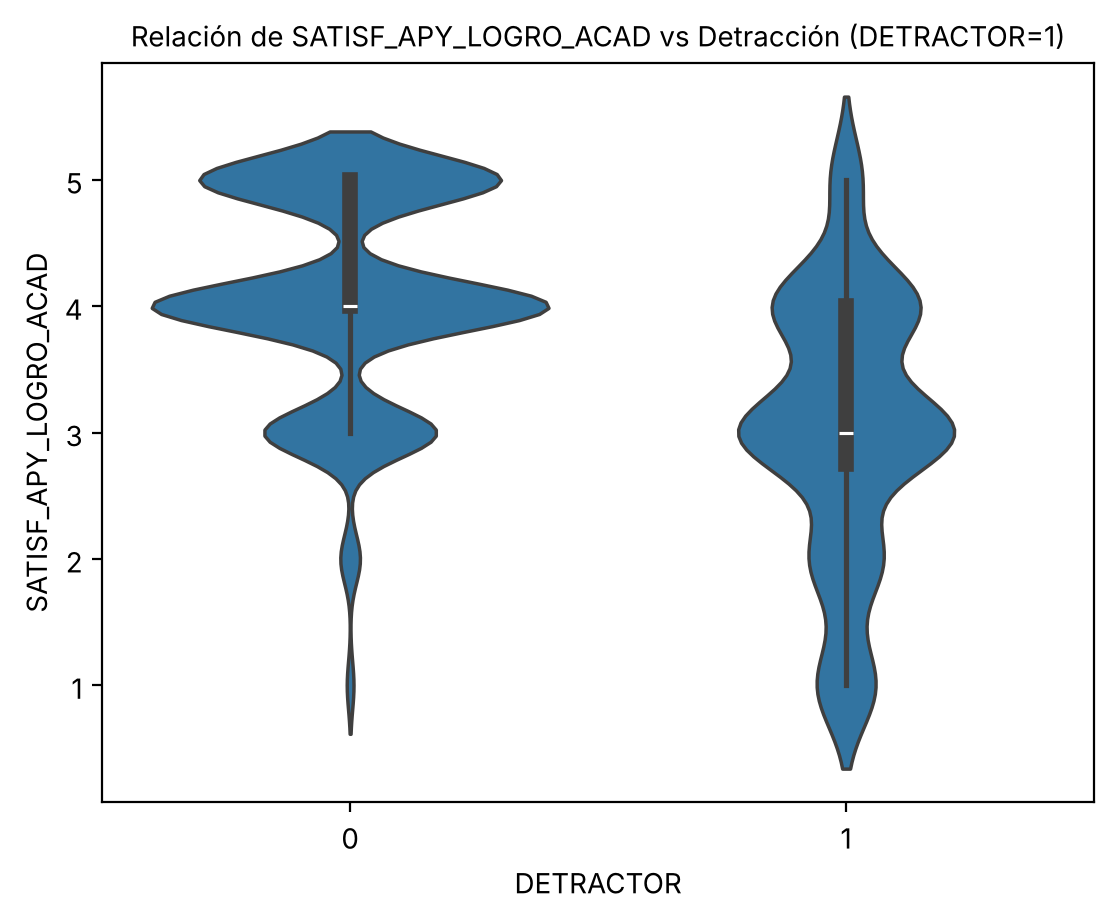

*** Prueba t para SATISF_APY_LOGRO_ACAD ***
Estadístico t: -19.62471
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.077291
1    3.039157
Name: SATISF_APY_LOGRO_ACAD, dtype: float64




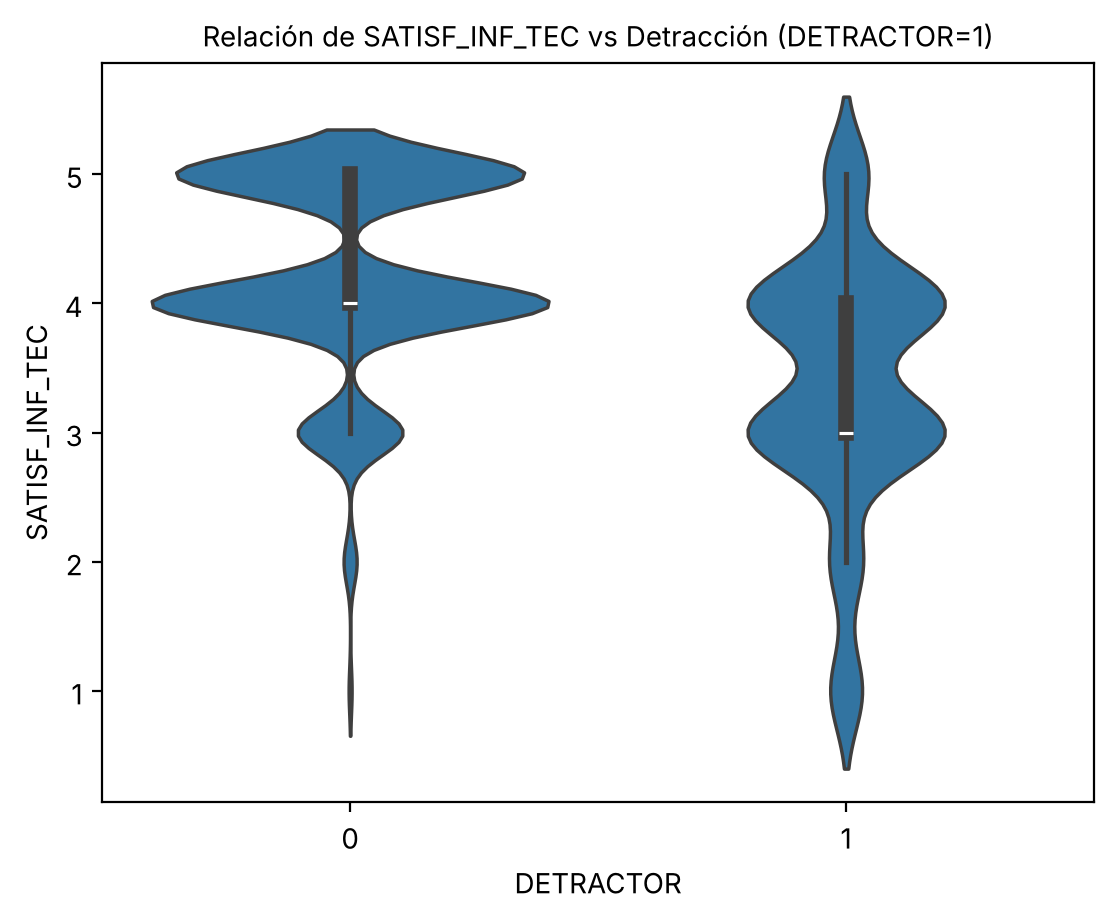

*** Prueba t para SATISF_INF_TEC ***
Estadístico t: -18.04310
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.240082
1    3.373494
Name: SATISF_INF_TEC, dtype: float64




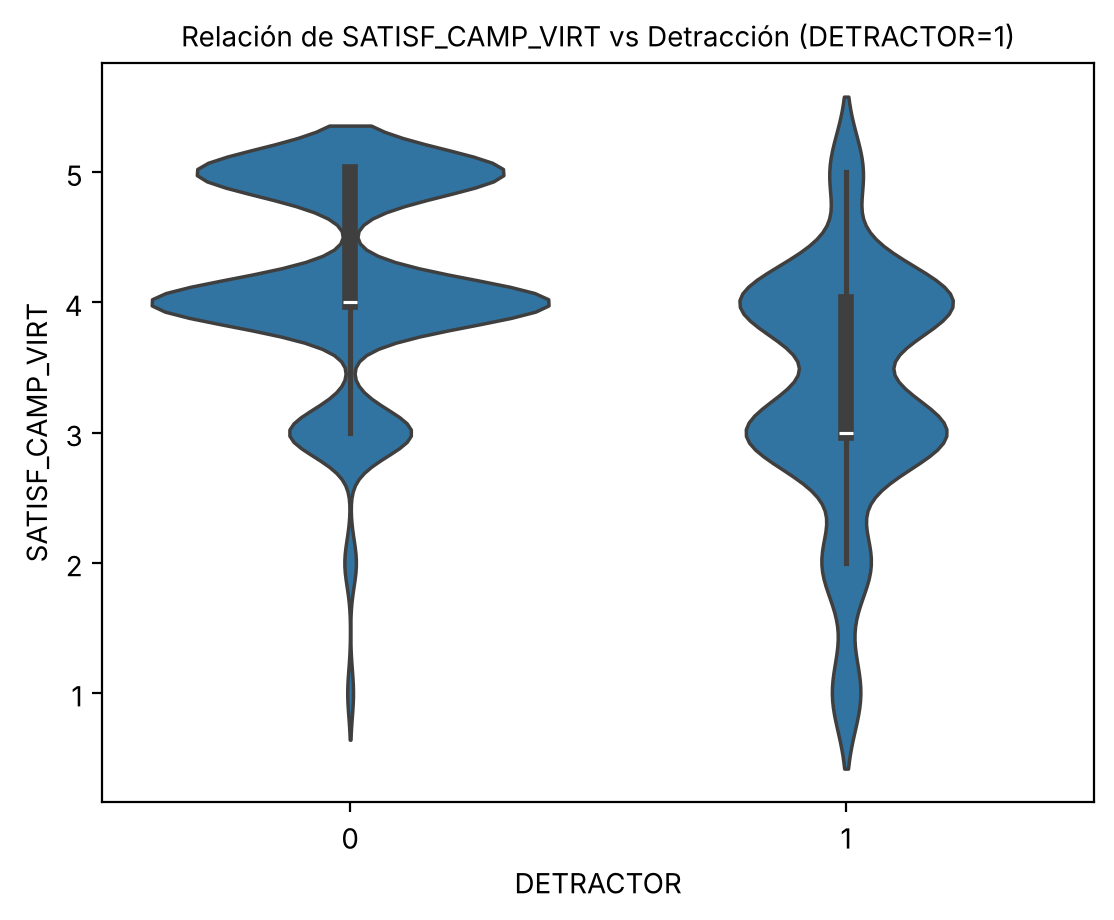

*** Prueba t para SATISF_CAMP_VIRT ***
Estadístico t: -17.21419
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.171683
1    3.331325
Name: SATISF_CAMP_VIRT, dtype: float64




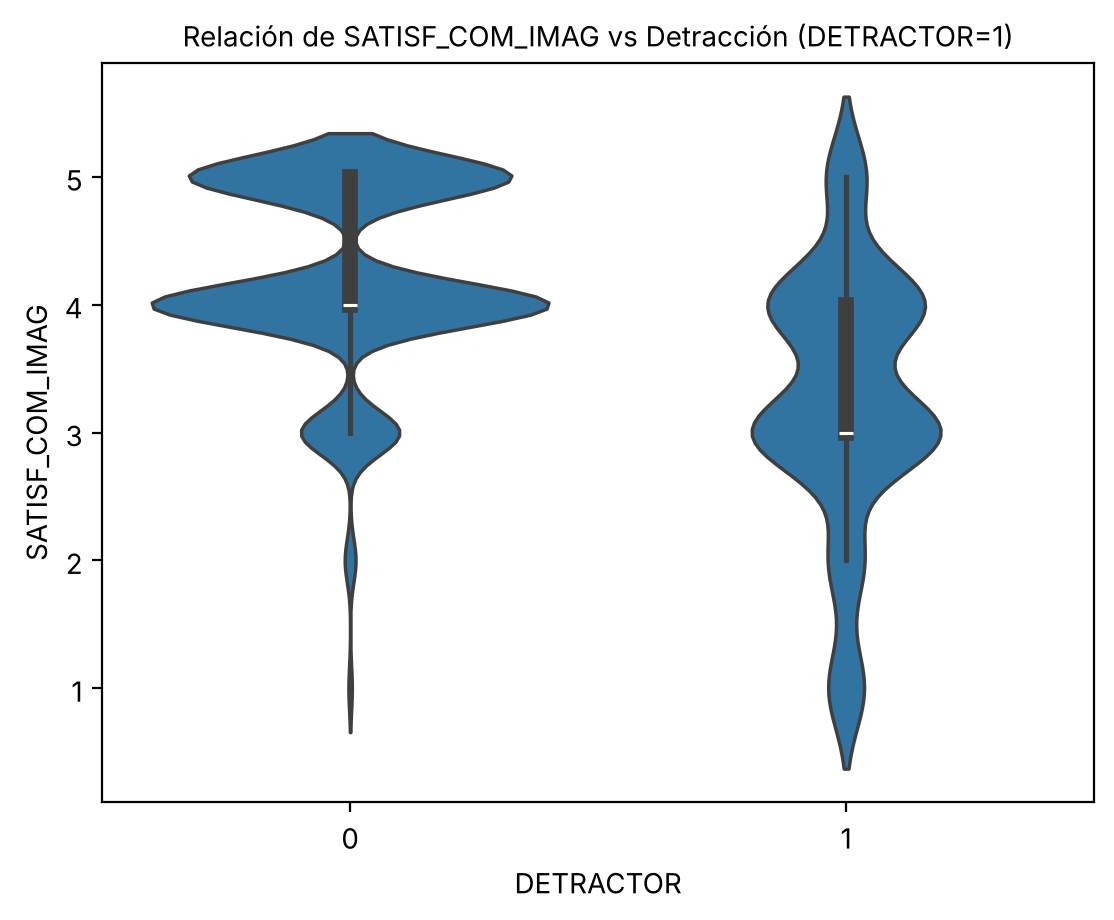

*** Prueba t para SATISF_COM_IMAG ***
Estadístico t: -19.66992
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.230506
1    3.283133
Name: SATISF_COM_IMAG, dtype: float64


[Satisfacción general] Variables que pasan la prueba t: ['SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']


                     ROC-AUC  Recall detractor  F1 detractor  Accuracy
Modelo                                                                
Regresión Logística    0.851             0.763         0.583     0.797
Random Forest          0.842             0.681         0.557     0.799
Gradient Boosting      0.837             0.699         0.569     0.803
Modelo elegido: Regresión Logística
Accuracy en prueba: 0.772
ROC-AUC en prueba: 0.827
Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.91      0.80      0.85       293
           1       0.42      0.64      0.51        66

    accuracy                           0.77       359
   macro avg       0.66      0.72      0.68       359
weighted avg       0.82      0.77      0.79       359



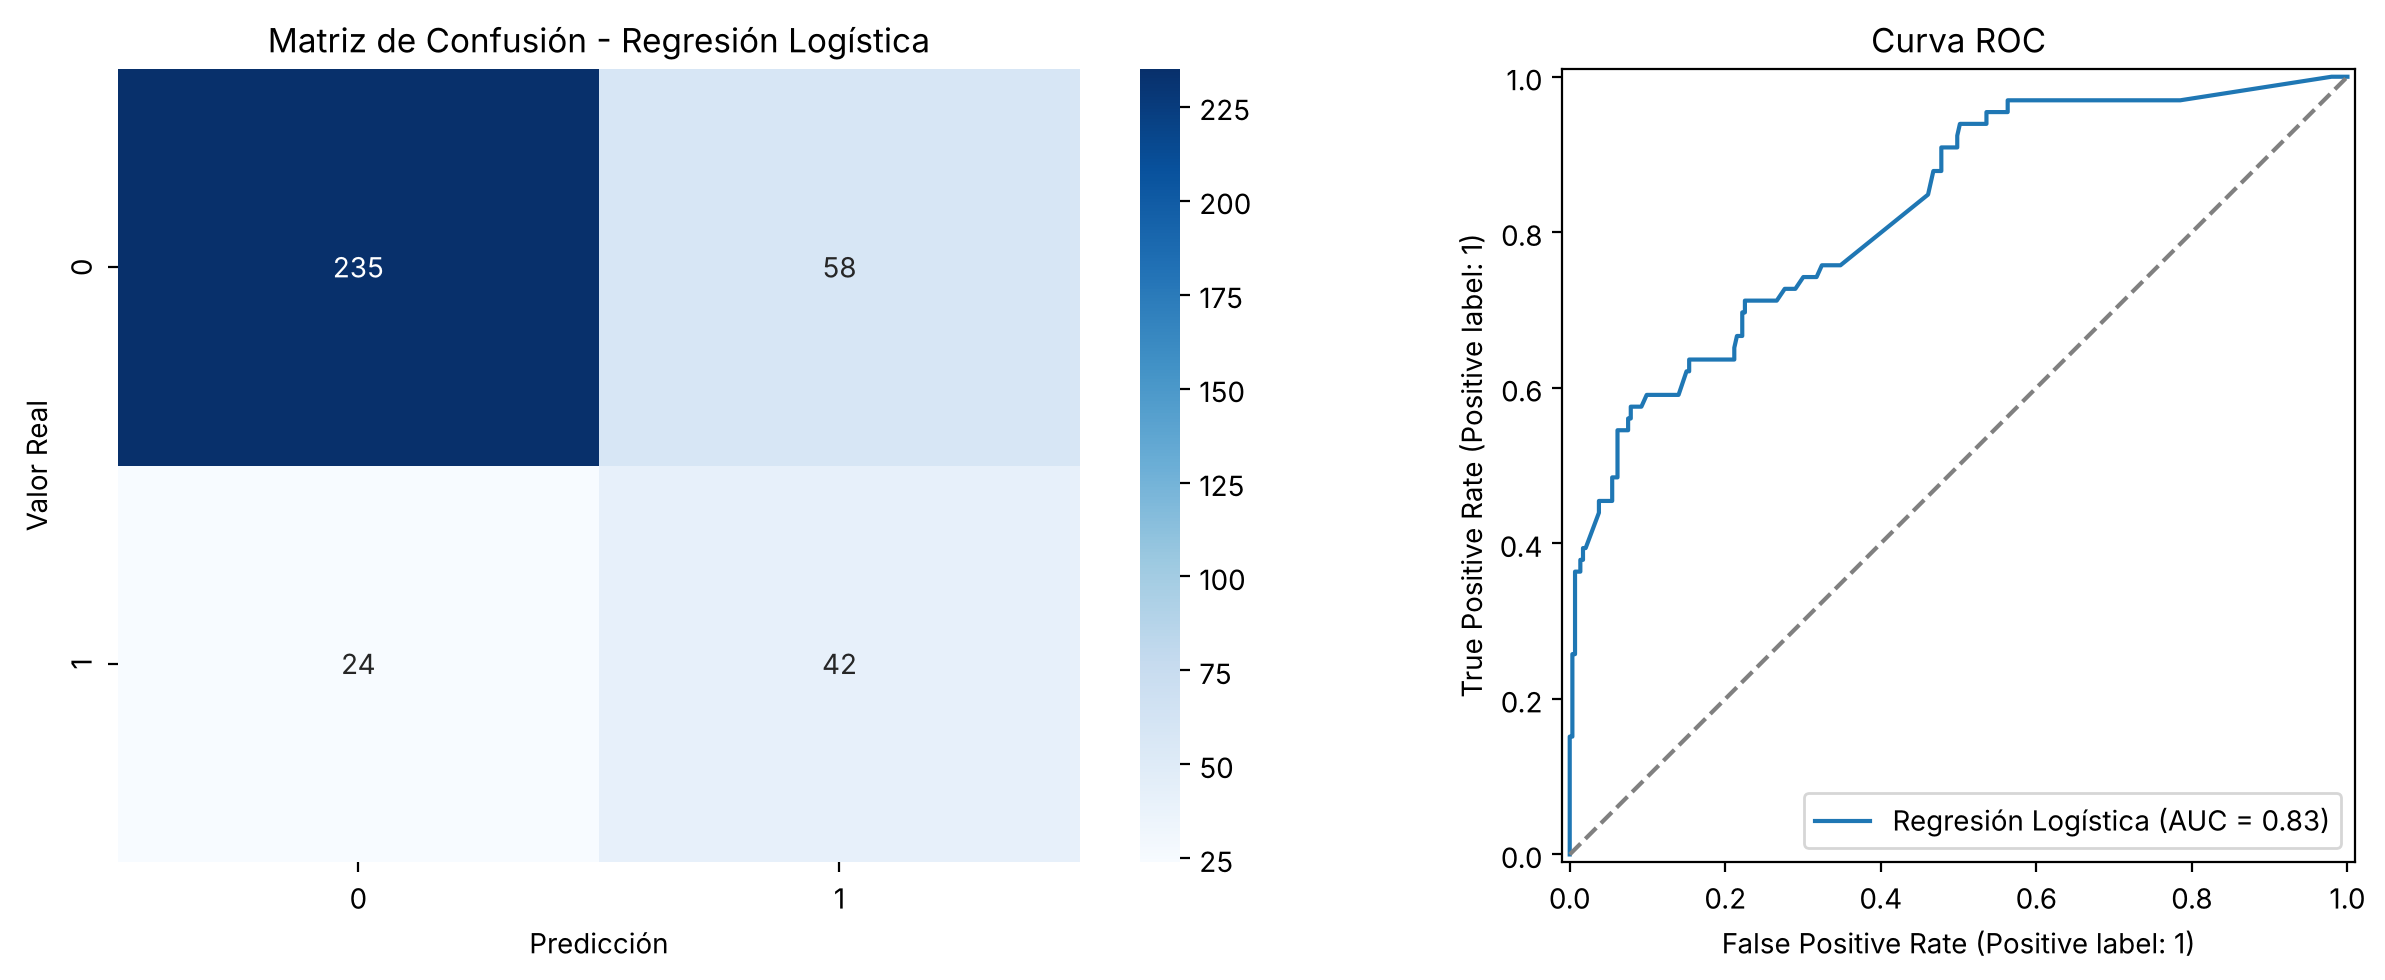

SATIF_ACAD               0.0591
SATISF_CAMP_VIRT         0.0065
SATISF_EXP              -0.0014
SATISF_SERV             -0.0016
SATISF_INF_TEC          -0.0024
SATISF_COM_IMAG         -0.0035
SATISF_ACT_SOST         -0.0045
SATISF_REG_ACAD         -0.0048
SATISF_APY_LOGRO_ACAD   -0.0063
dtype: float64


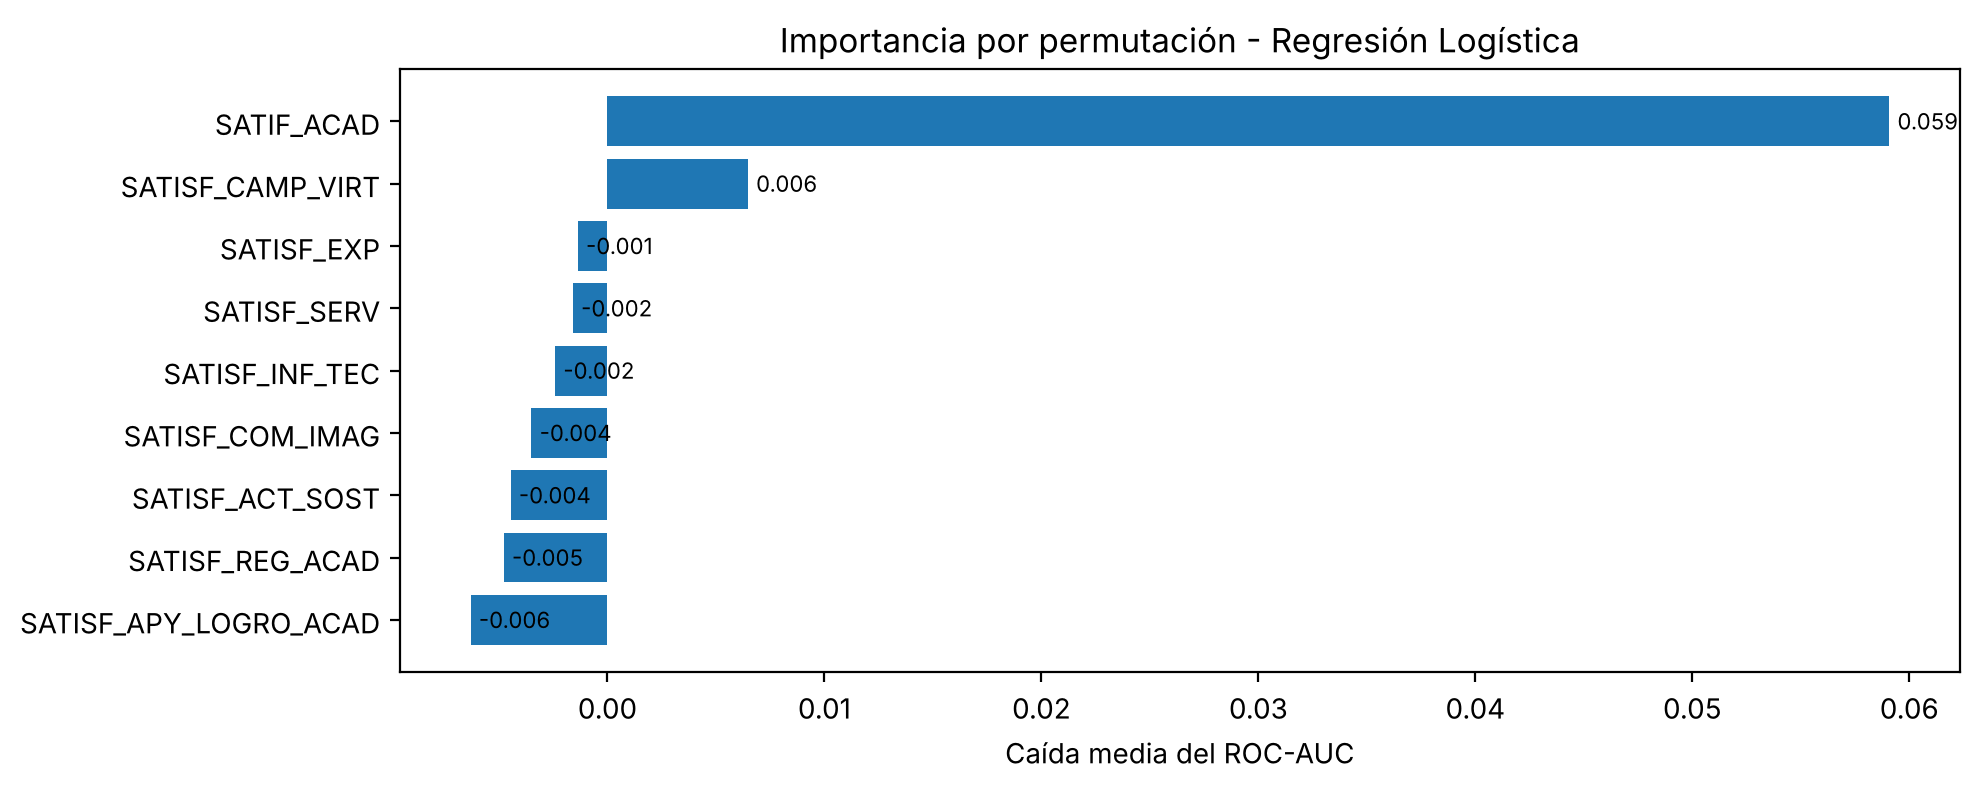

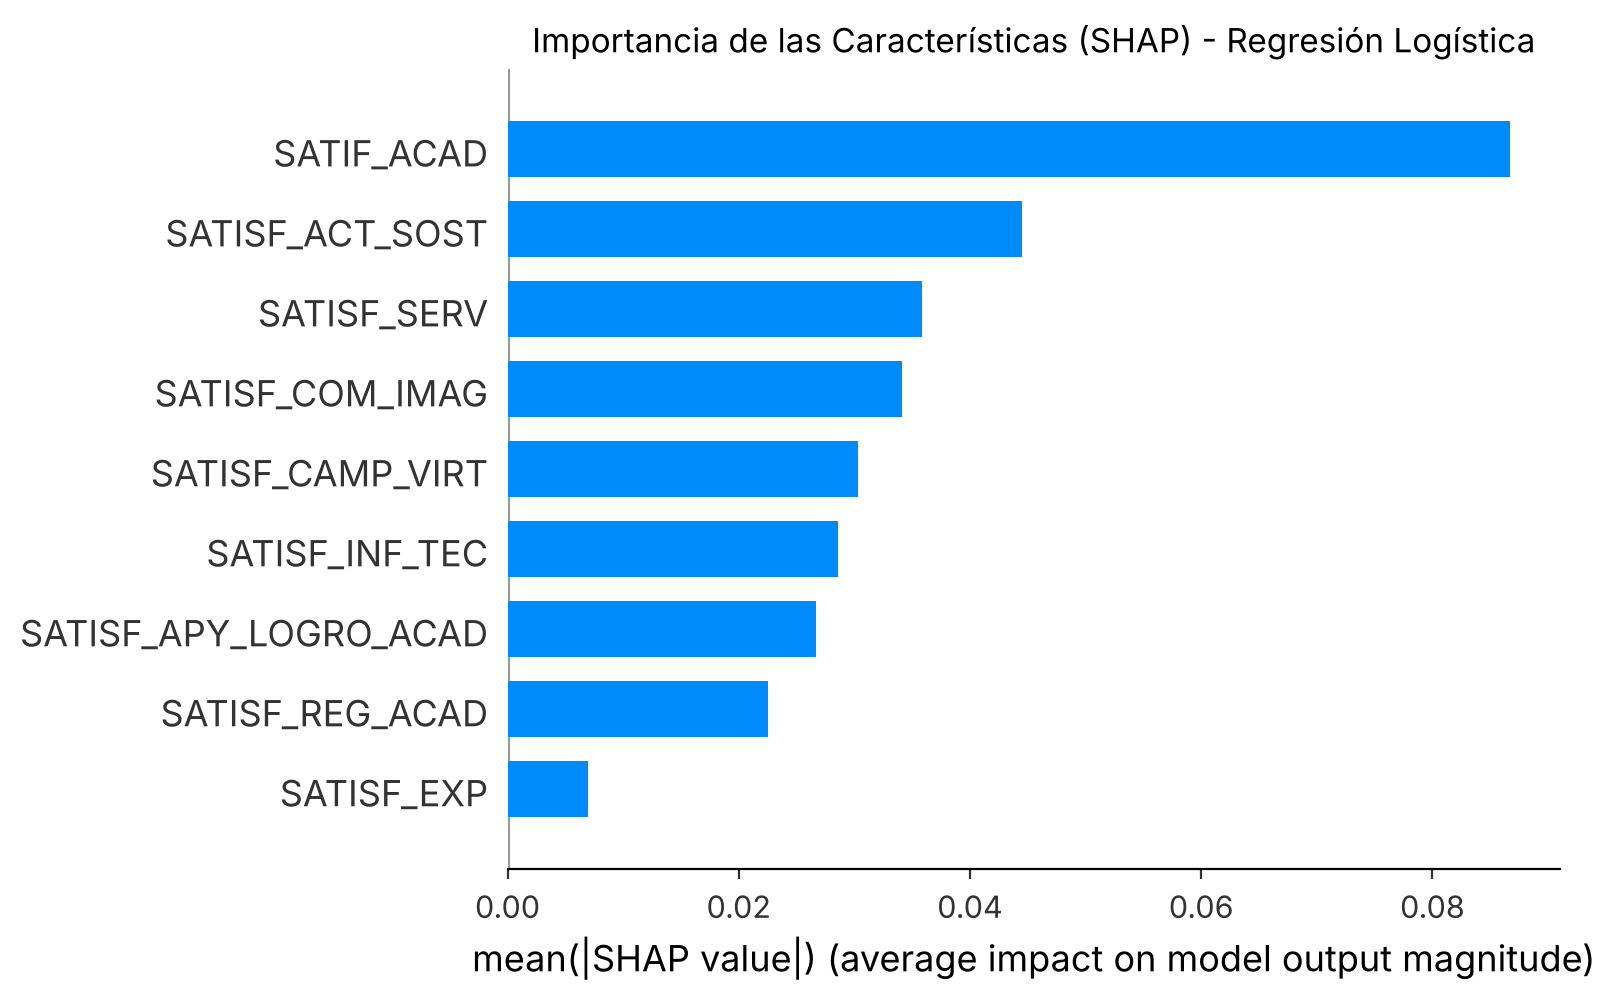

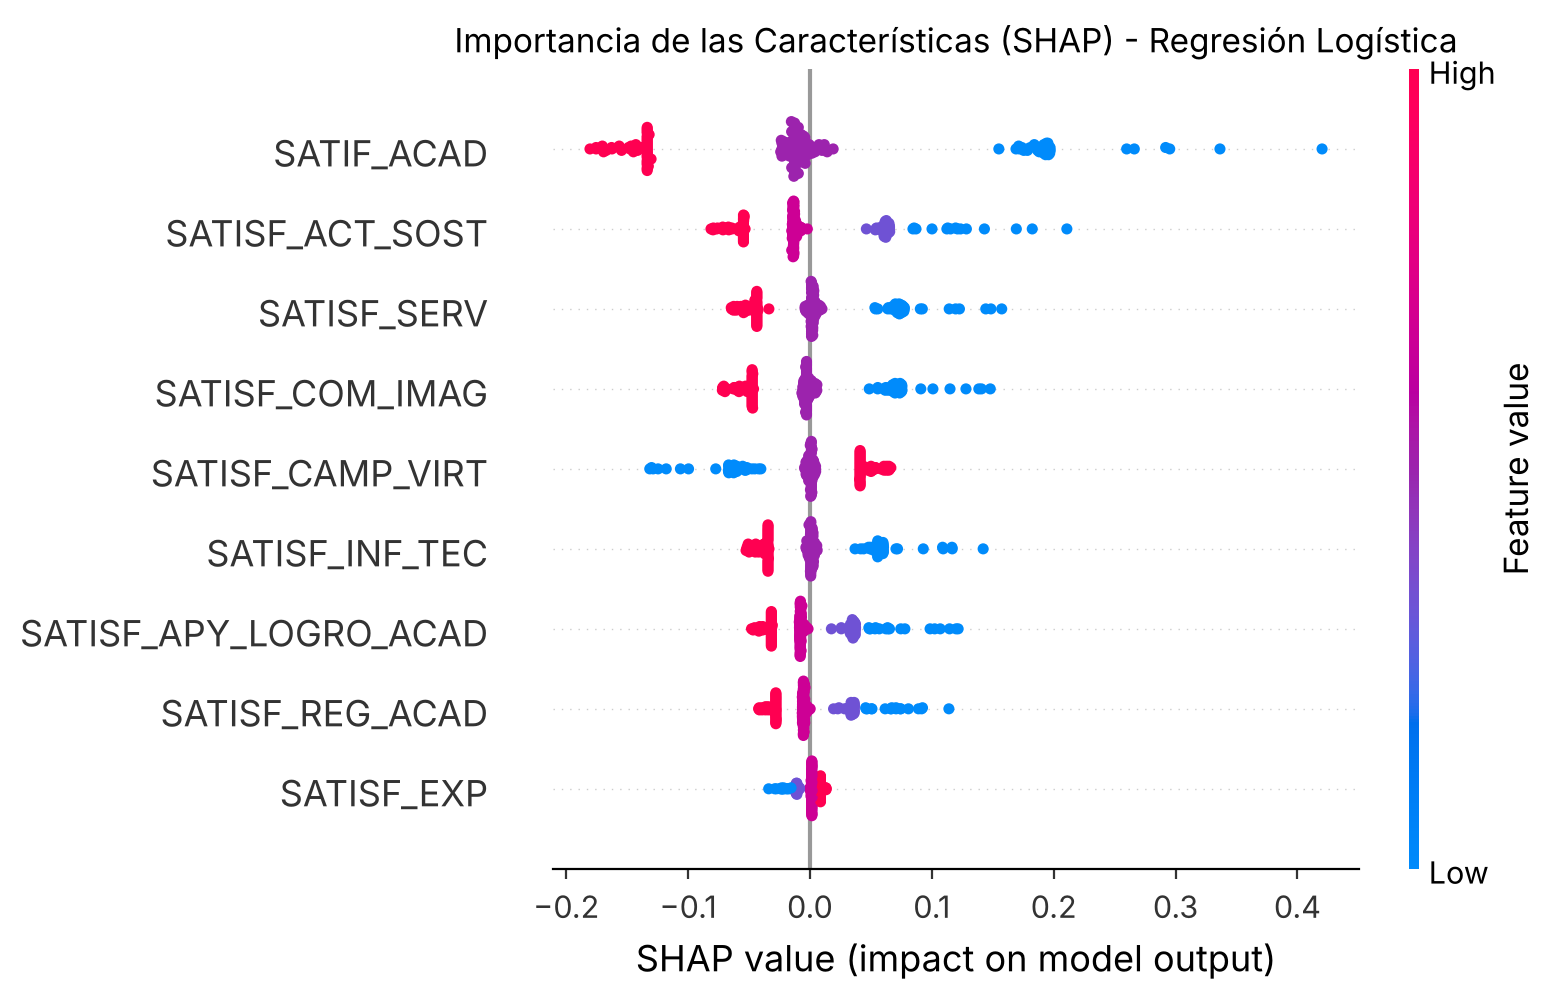

In [7]:
resultados['Satisfacción general'] = modelar_bloque(estudiantes_CUSCO, cols_general, 'Satisfacción general')

# **2. Factores de la Satisfacción Académica**
**P3. ¿QUÉ TAN SATISFECHO TE ENCUENTRAS CON EL ÁREA ACADÉMICA DE LA UNIVERSIDAD CONTINENTAL?**

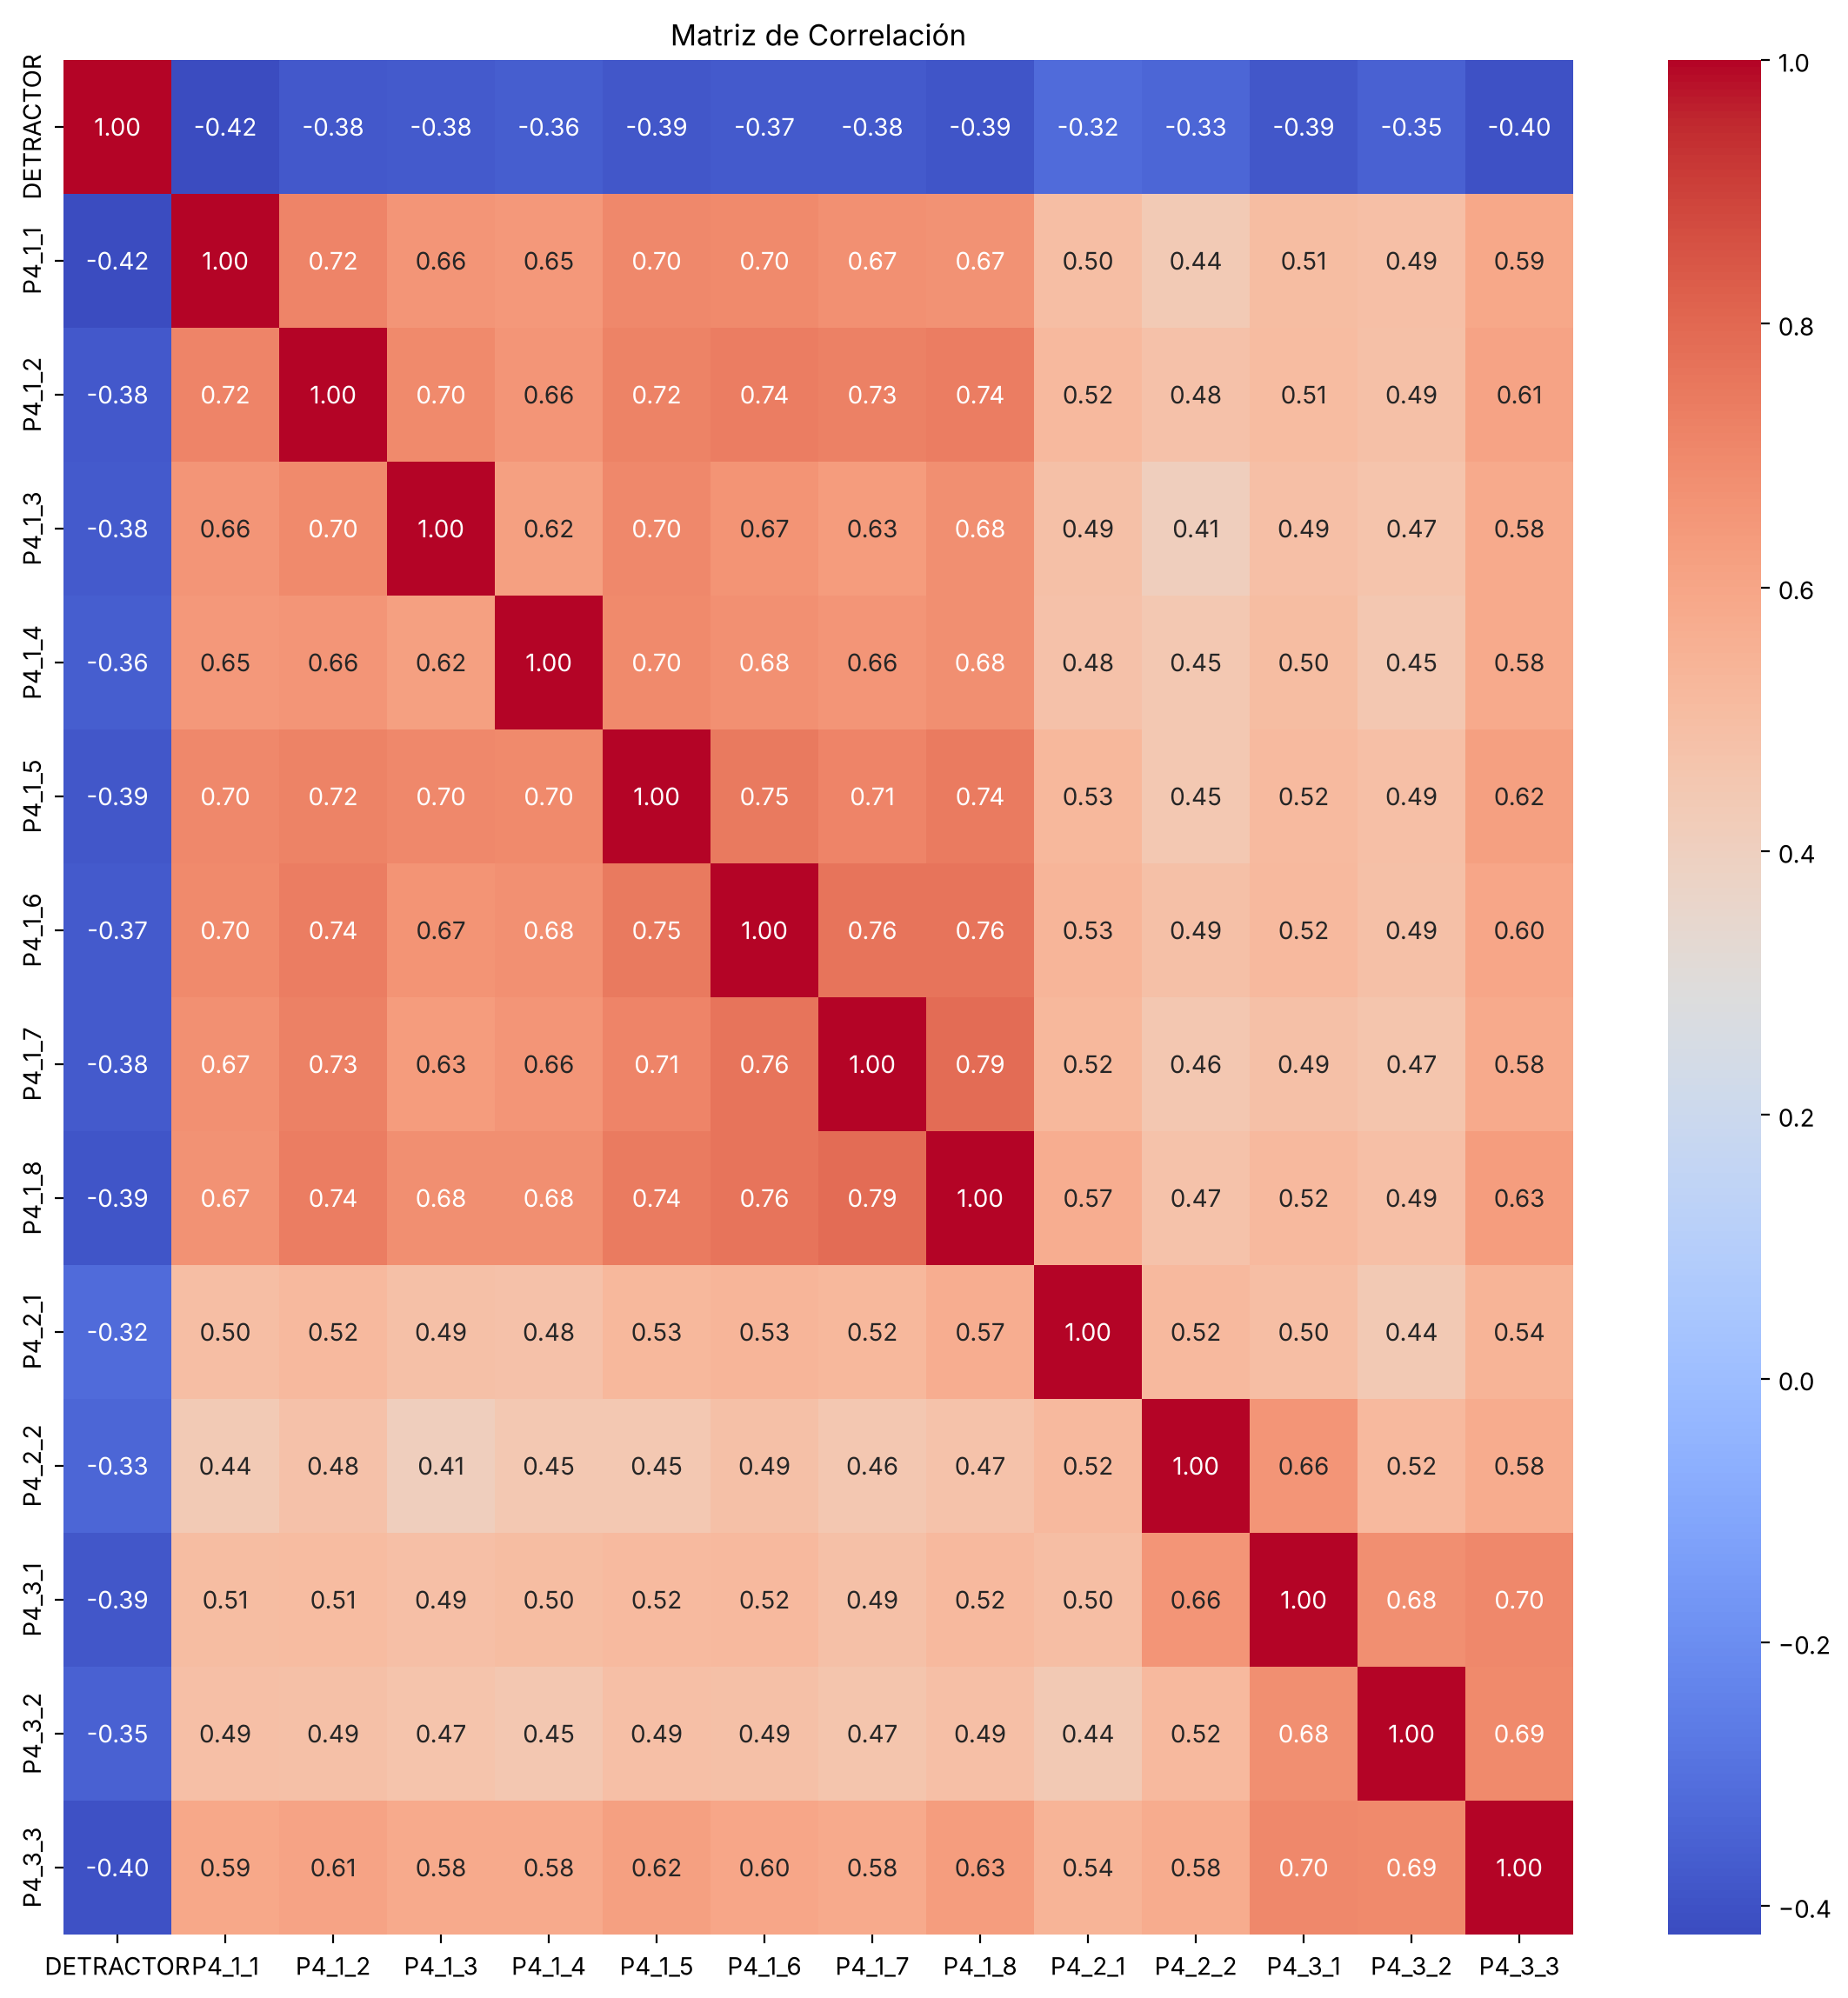

In [8]:
cols_academica = ['P4_1_1', 'P4_1_2', 'P4_1_3', 'P4_1_4', 'P4_1_5', 'P4_1_6', 'P4_1_7', 'P4_1_8',
                  'P4_2_1', 'P4_2_2', 'P4_3_1', 'P4_3_2', 'P4_3_3']
matriz_correlacion(estudiantes_CUSCO, cols_academica, 14)

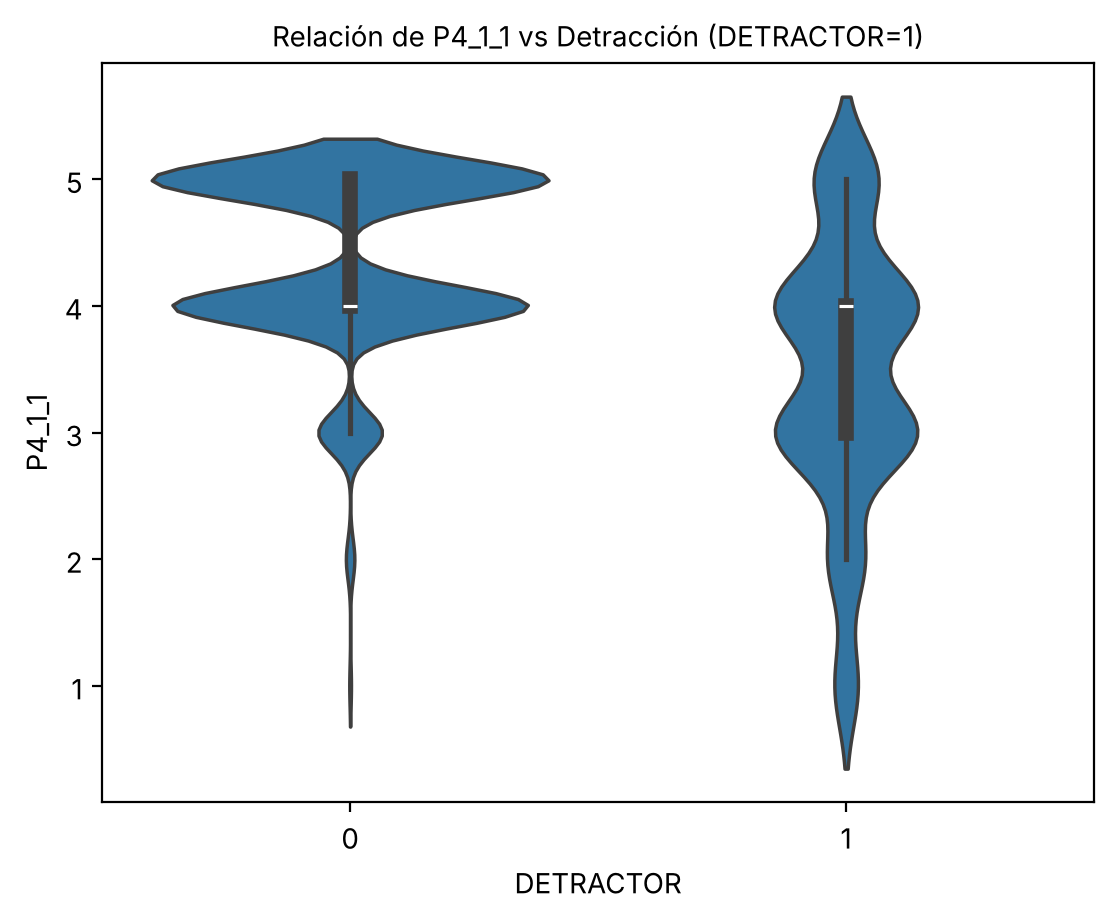

*** Prueba t para P4_1_1 ***
Estadístico t: -19.68279
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.376197
1    3.457831
Name: P4_1_1, dtype: float64




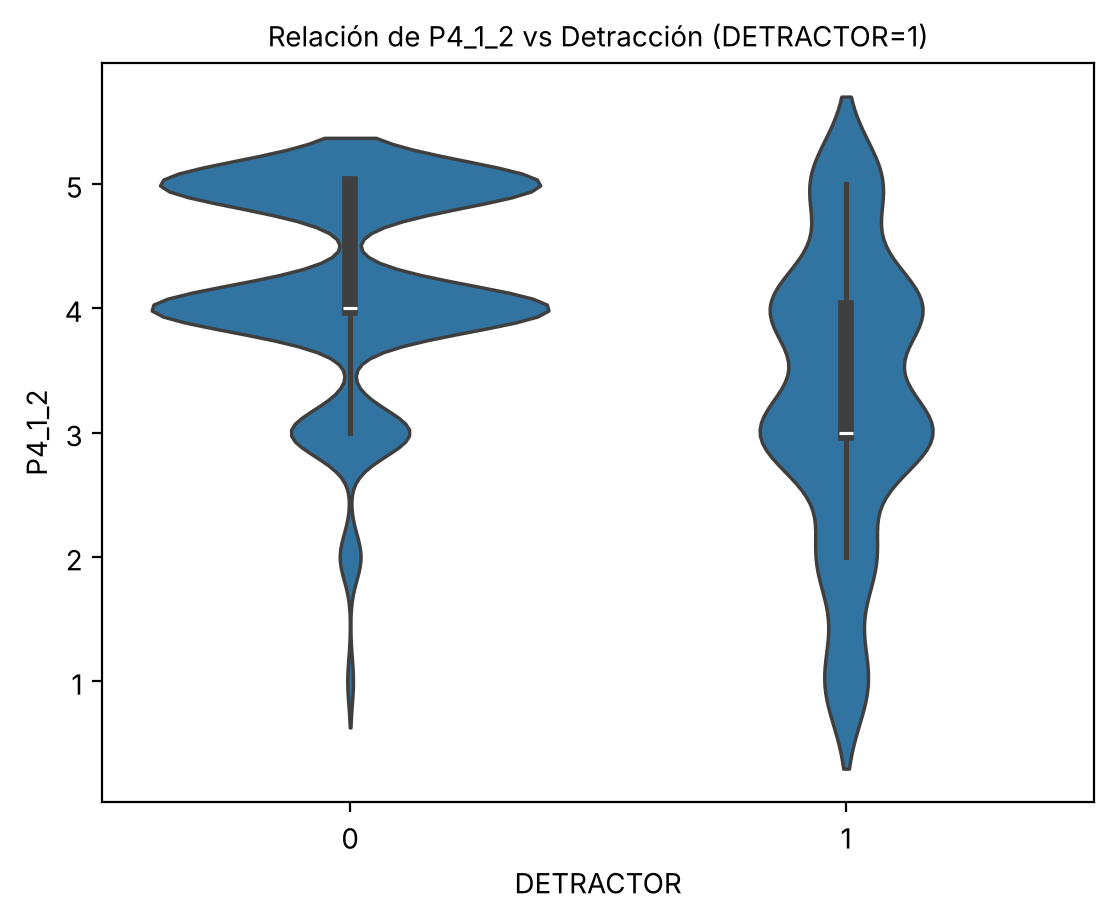

*** Prueba t para P4_1_2 ***
Estadístico t: -17.40127
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.219562
1    3.301205
Name: P4_1_2, dtype: float64




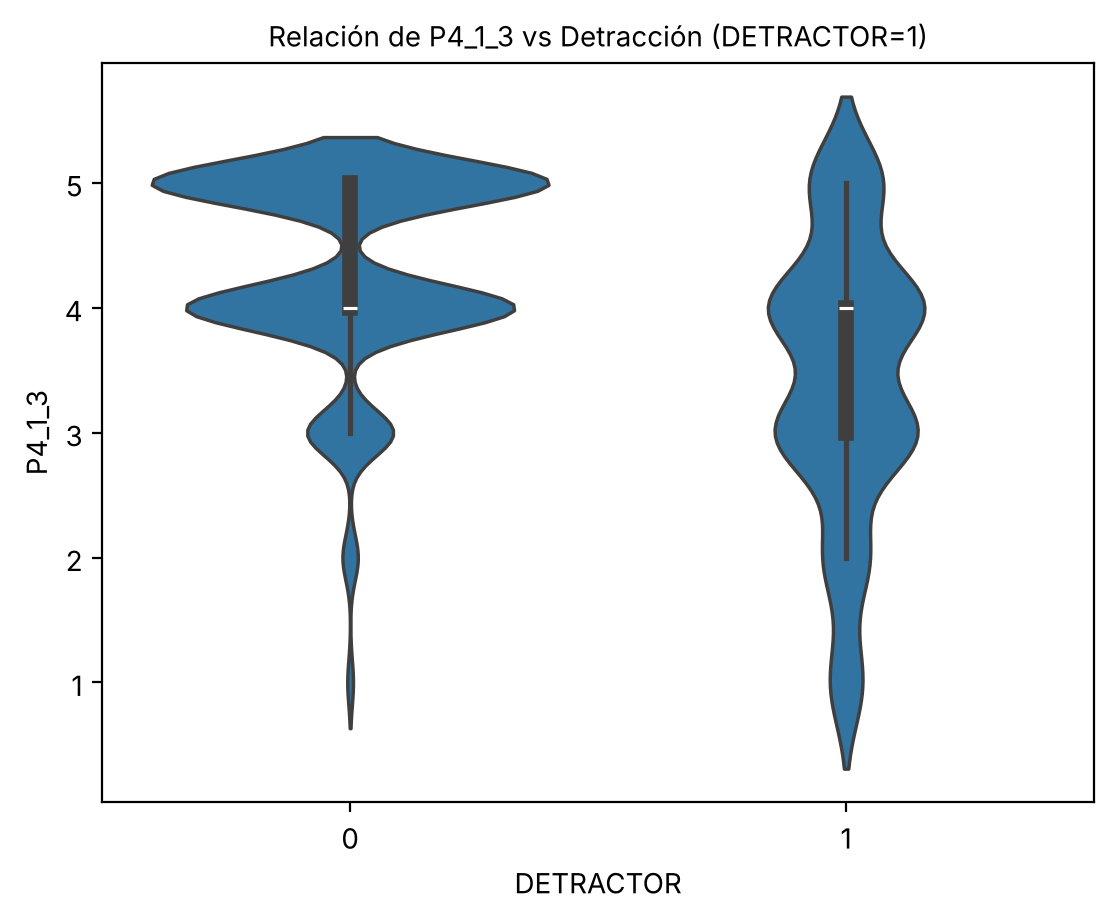

*** Prueba t para P4_1_3 ***
Estadístico t: -17.20555
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.316005
1    3.424699
Name: P4_1_3, dtype: float64




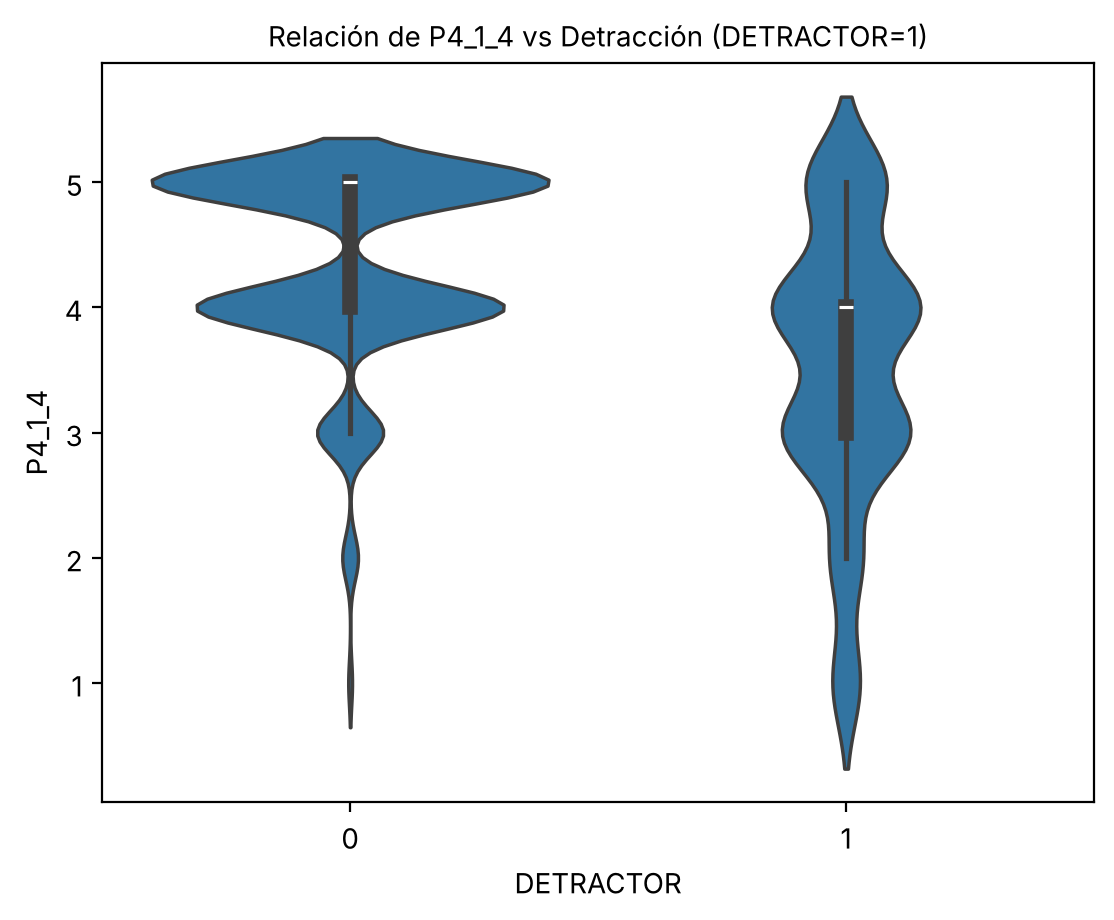

*** Prueba t para P4_1_4 ***
Estadístico t: -16.54274
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.365253
1    3.530120
Name: P4_1_4, dtype: float64




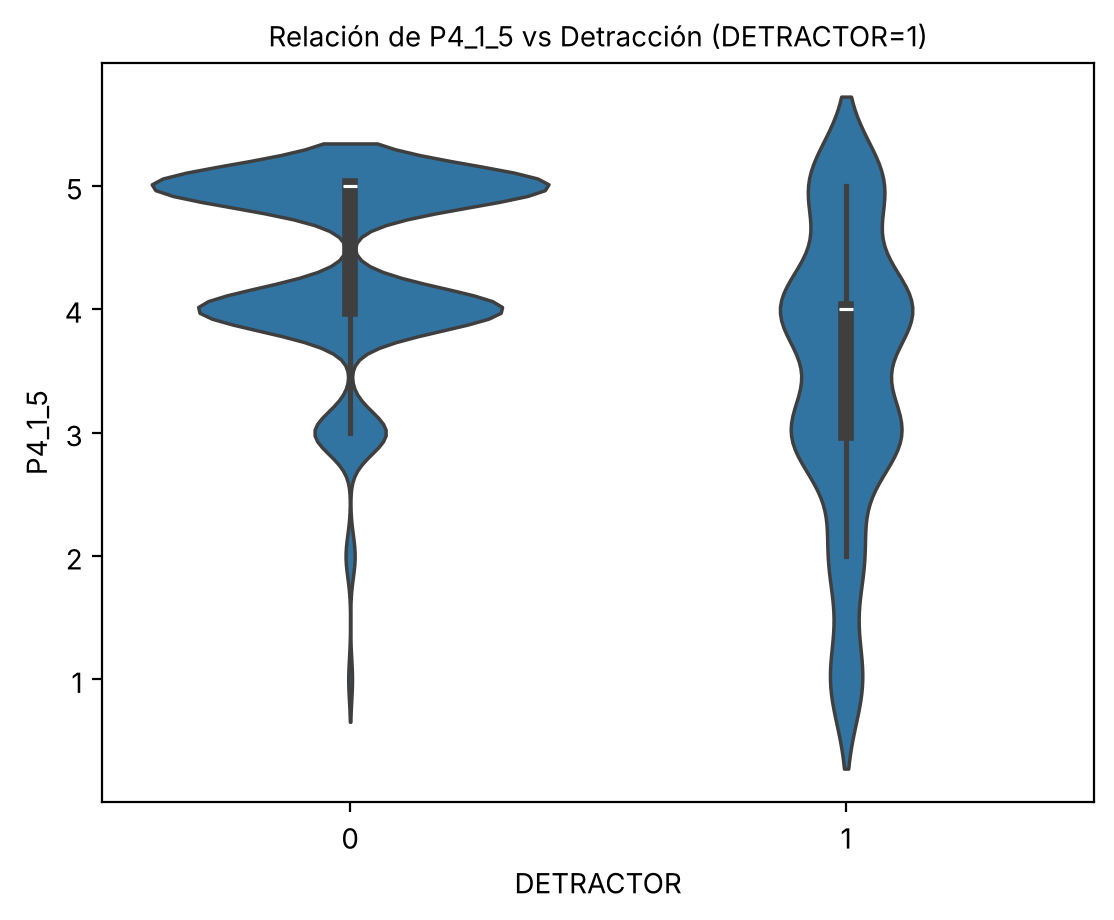

*** Prueba t para P4_1_5 ***
Estadístico t: -17.83171
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.376197
1    3.475904
Name: P4_1_5, dtype: float64




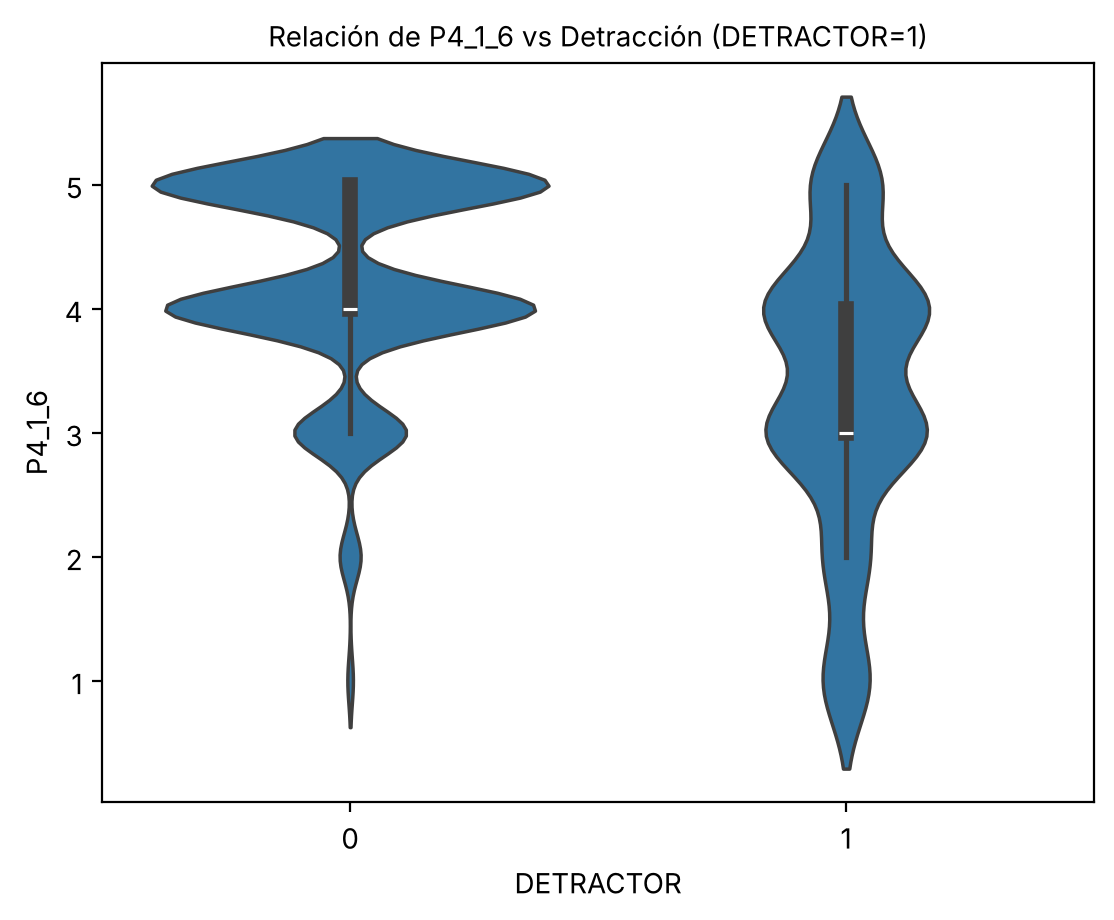

*** Prueba t para P4_1_6 ***
Estadístico t: -17.08111
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.248974
1    3.340361
Name: P4_1_6, dtype: float64




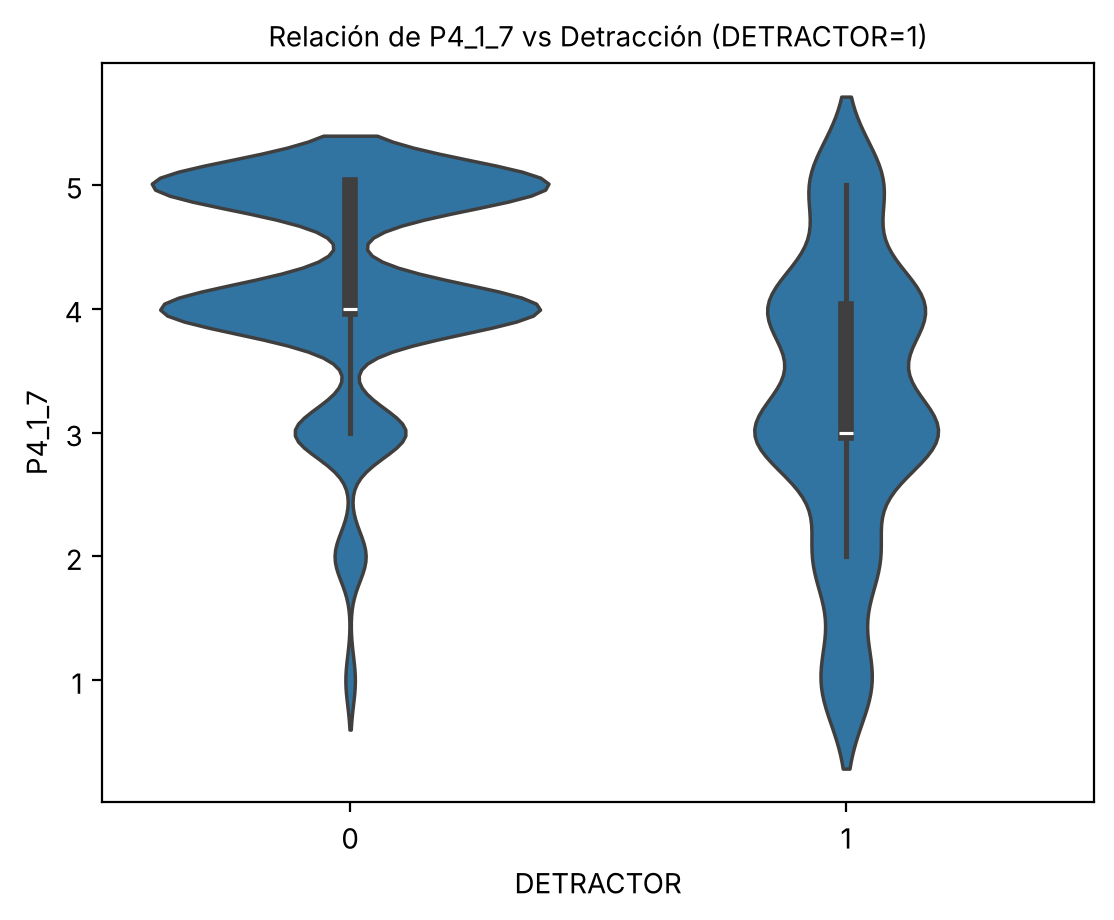

*** Prueba t para P4_1_7 ***
Estadístico t: -17.17509
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.209986
1    3.256024
Name: P4_1_7, dtype: float64




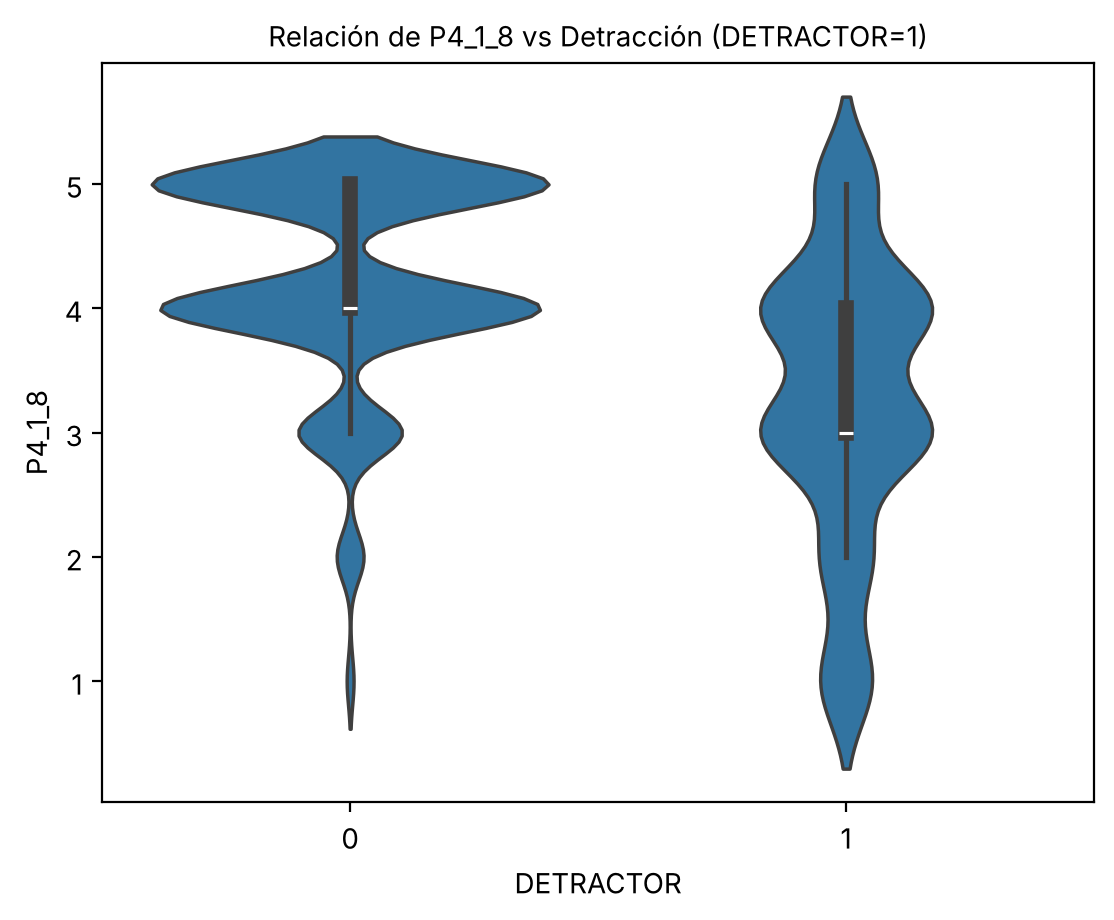

*** Prueba t para P4_1_8 ***
Estadístico t: -17.97325
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.238714
1    3.271084
Name: P4_1_8, dtype: float64




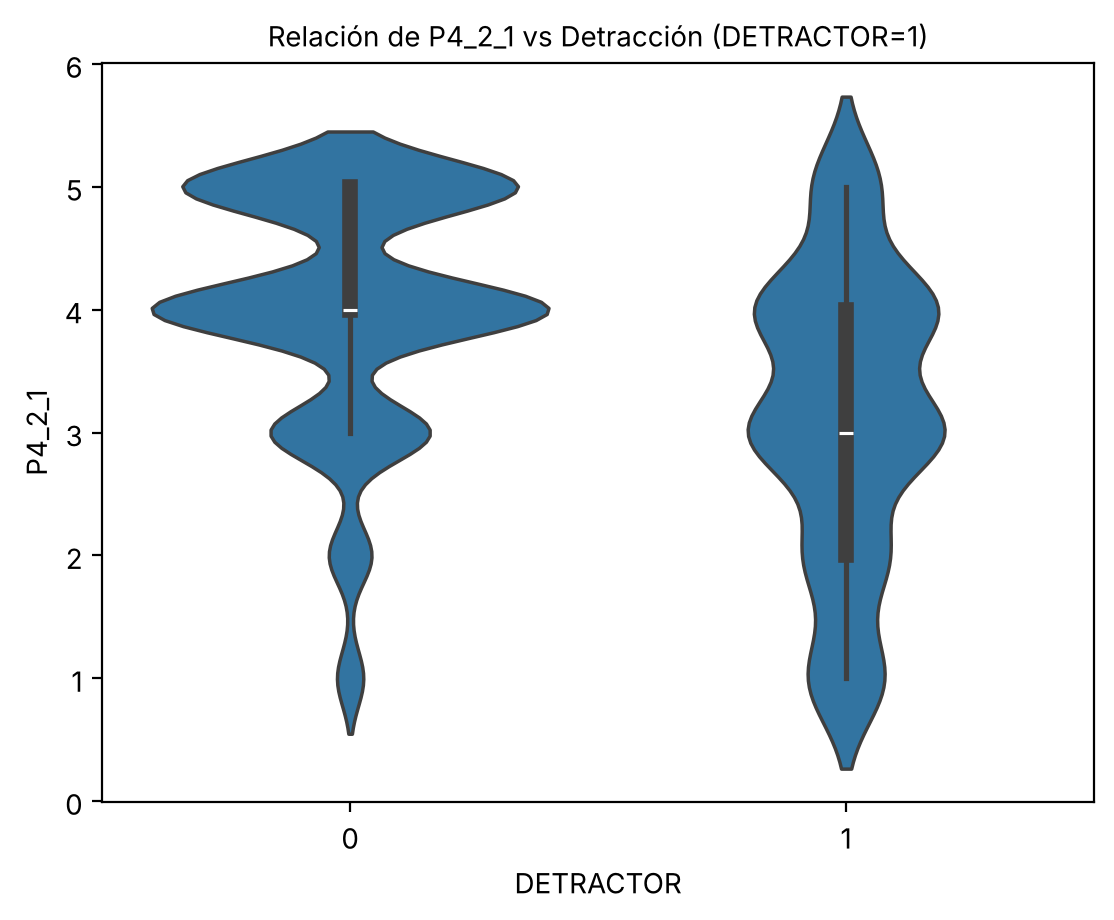

*** Prueba t para P4_2_1 ***
Estadístico t: -14.31312
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.011628
1    3.132530
Name: P4_2_1, dtype: float64




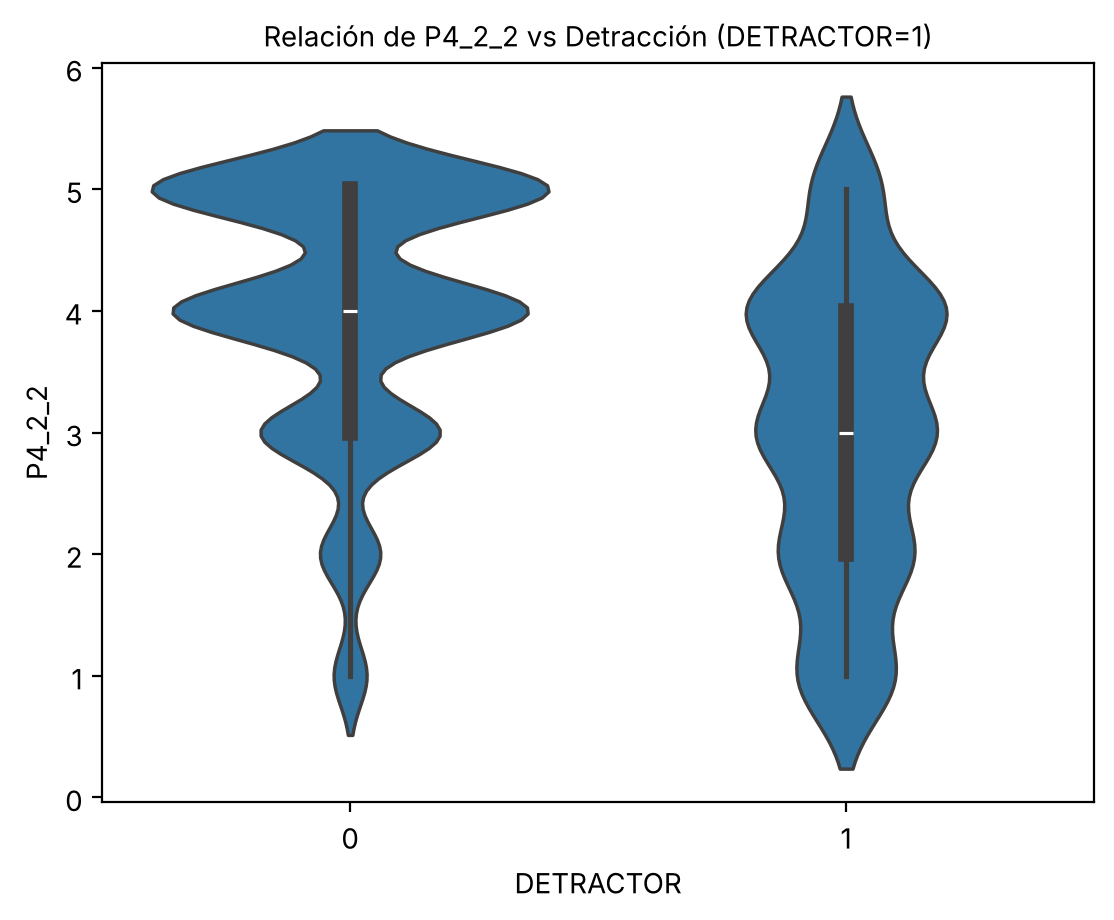

*** Prueba t para P4_2_2 ***
Estadístico t: -15.00656
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    3.997948
1    3.015060
Name: P4_2_2, dtype: float64




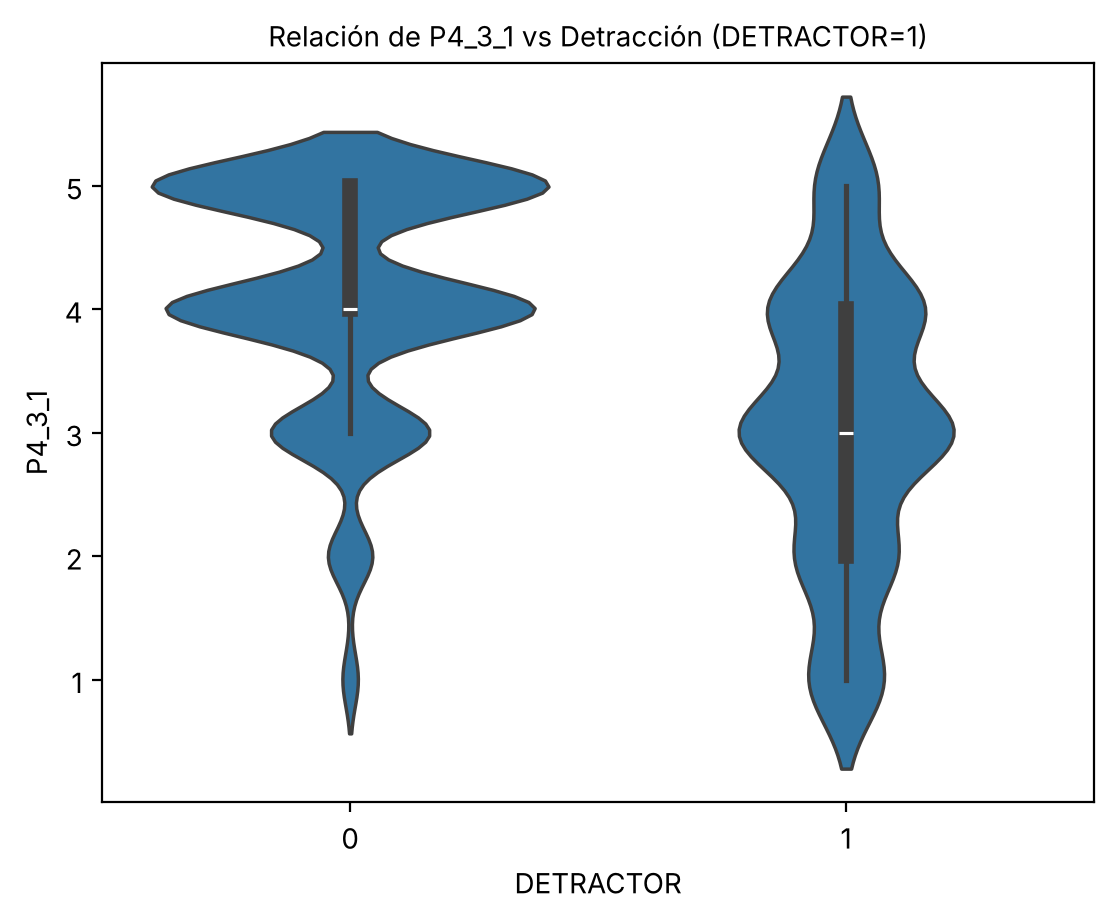

*** Prueba t para P4_3_1 ***
Estadístico t: -17.72882
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.103967
1    3.048193
Name: P4_3_1, dtype: float64




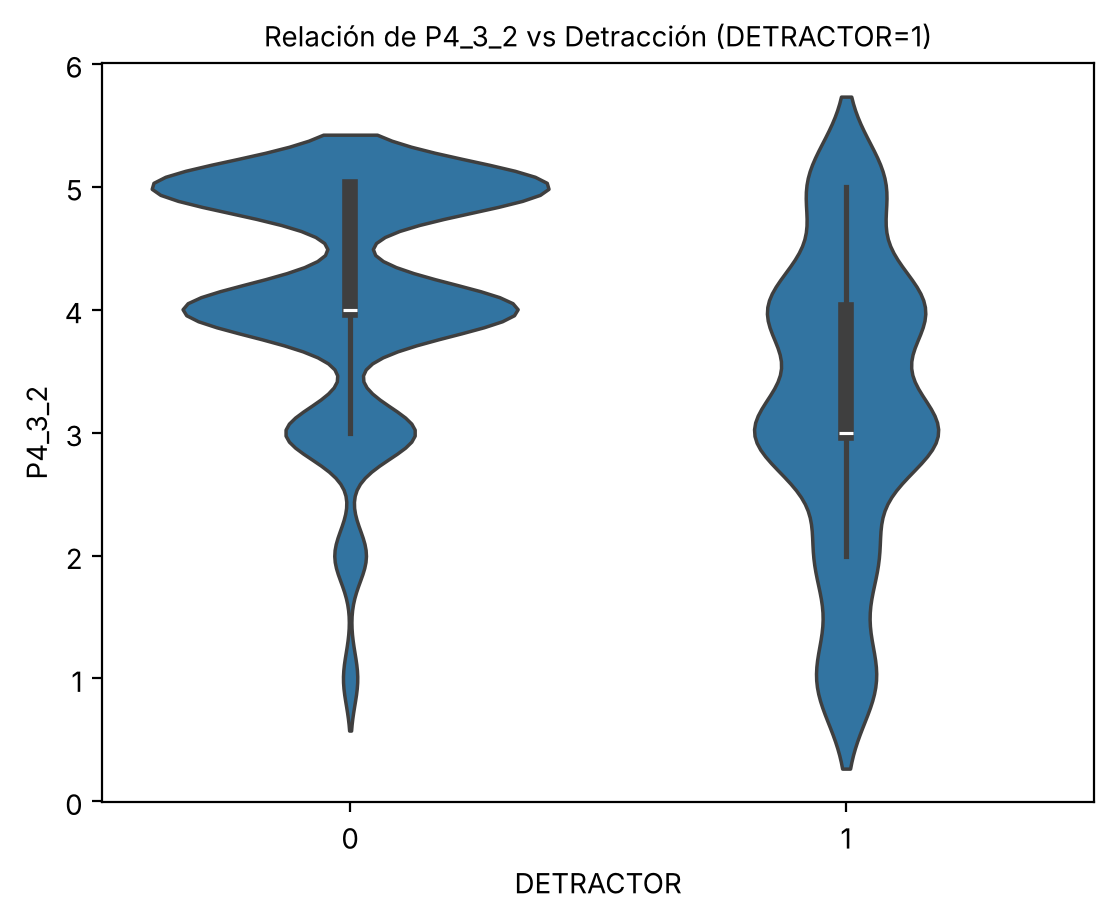

*** Prueba t para P4_3_2 ***
Estadístico t: -15.97059
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.177839
1    3.240964
Name: P4_3_2, dtype: float64




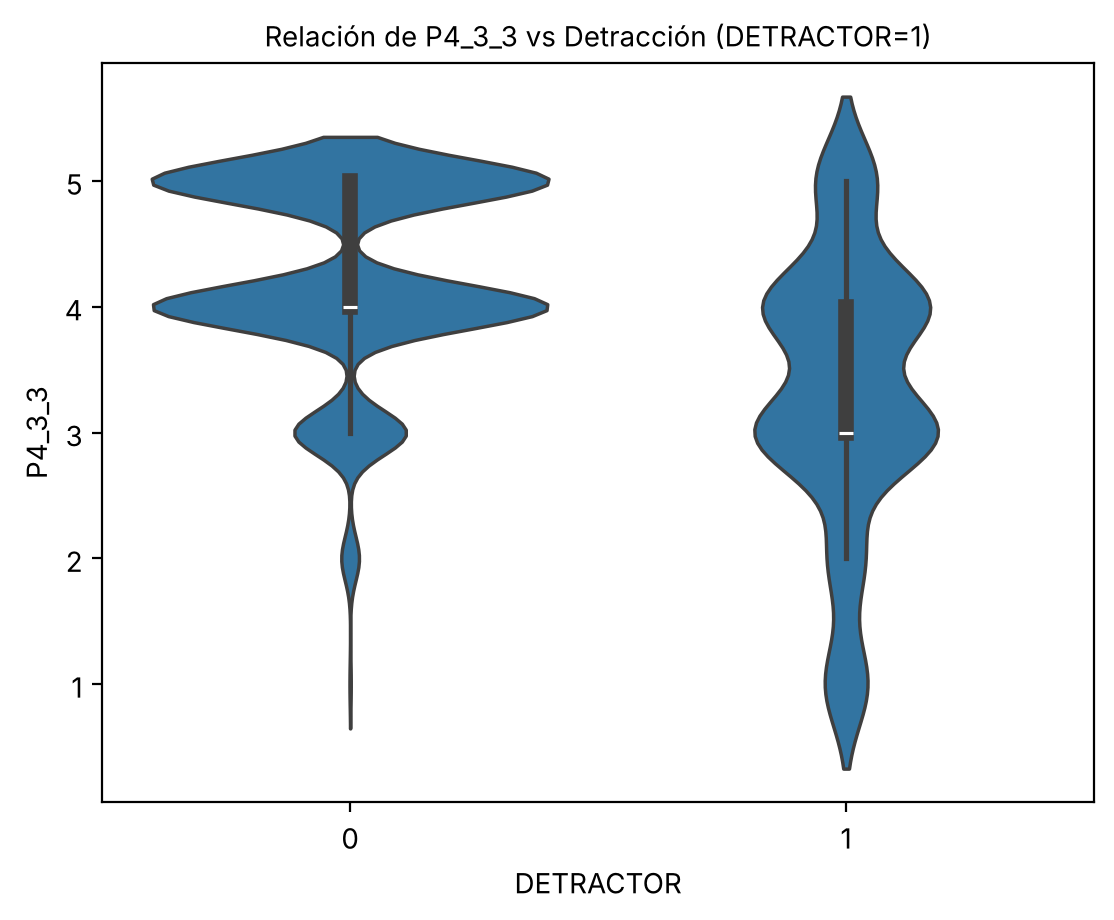

*** Prueba t para P4_3_3 ***
Estadístico t: -18.58760
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.266758
1    3.337349
Name: P4_3_3, dtype: float64


[Satisfacción académica (P4)] Variables que pasan la prueba t: ['P4_1_1', 'P4_1_2', 'P4_1_3', 'P4_1_4', 'P4_1_5', 'P4_1_6', 'P4_1_7', 'P4_1_8', 'P4_2_1', 'P4_2_2', 'P4_3_1', 'P4_3_2', 'P4_3_3']


                     ROC-AUC  Recall detractor  F1 detractor  Accuracy
Modelo                                                                
Random Forest          0.812             0.650         0.541     0.796
Regresión Logística    0.811             0.688         0.518     0.763
Gradient Boosting      0.798             0.624         0.523     0.790


Modelo elegido: Random Forest
Accuracy en prueba: 0.777
ROC-AUC en prueba: 0.785
Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.90      0.82      0.86       293
           1       0.43      0.61      0.50        66

    accuracy                           0.78       359
   macro avg       0.66      0.71      0.68       359
weighted avg       0.81      0.78      0.79       359



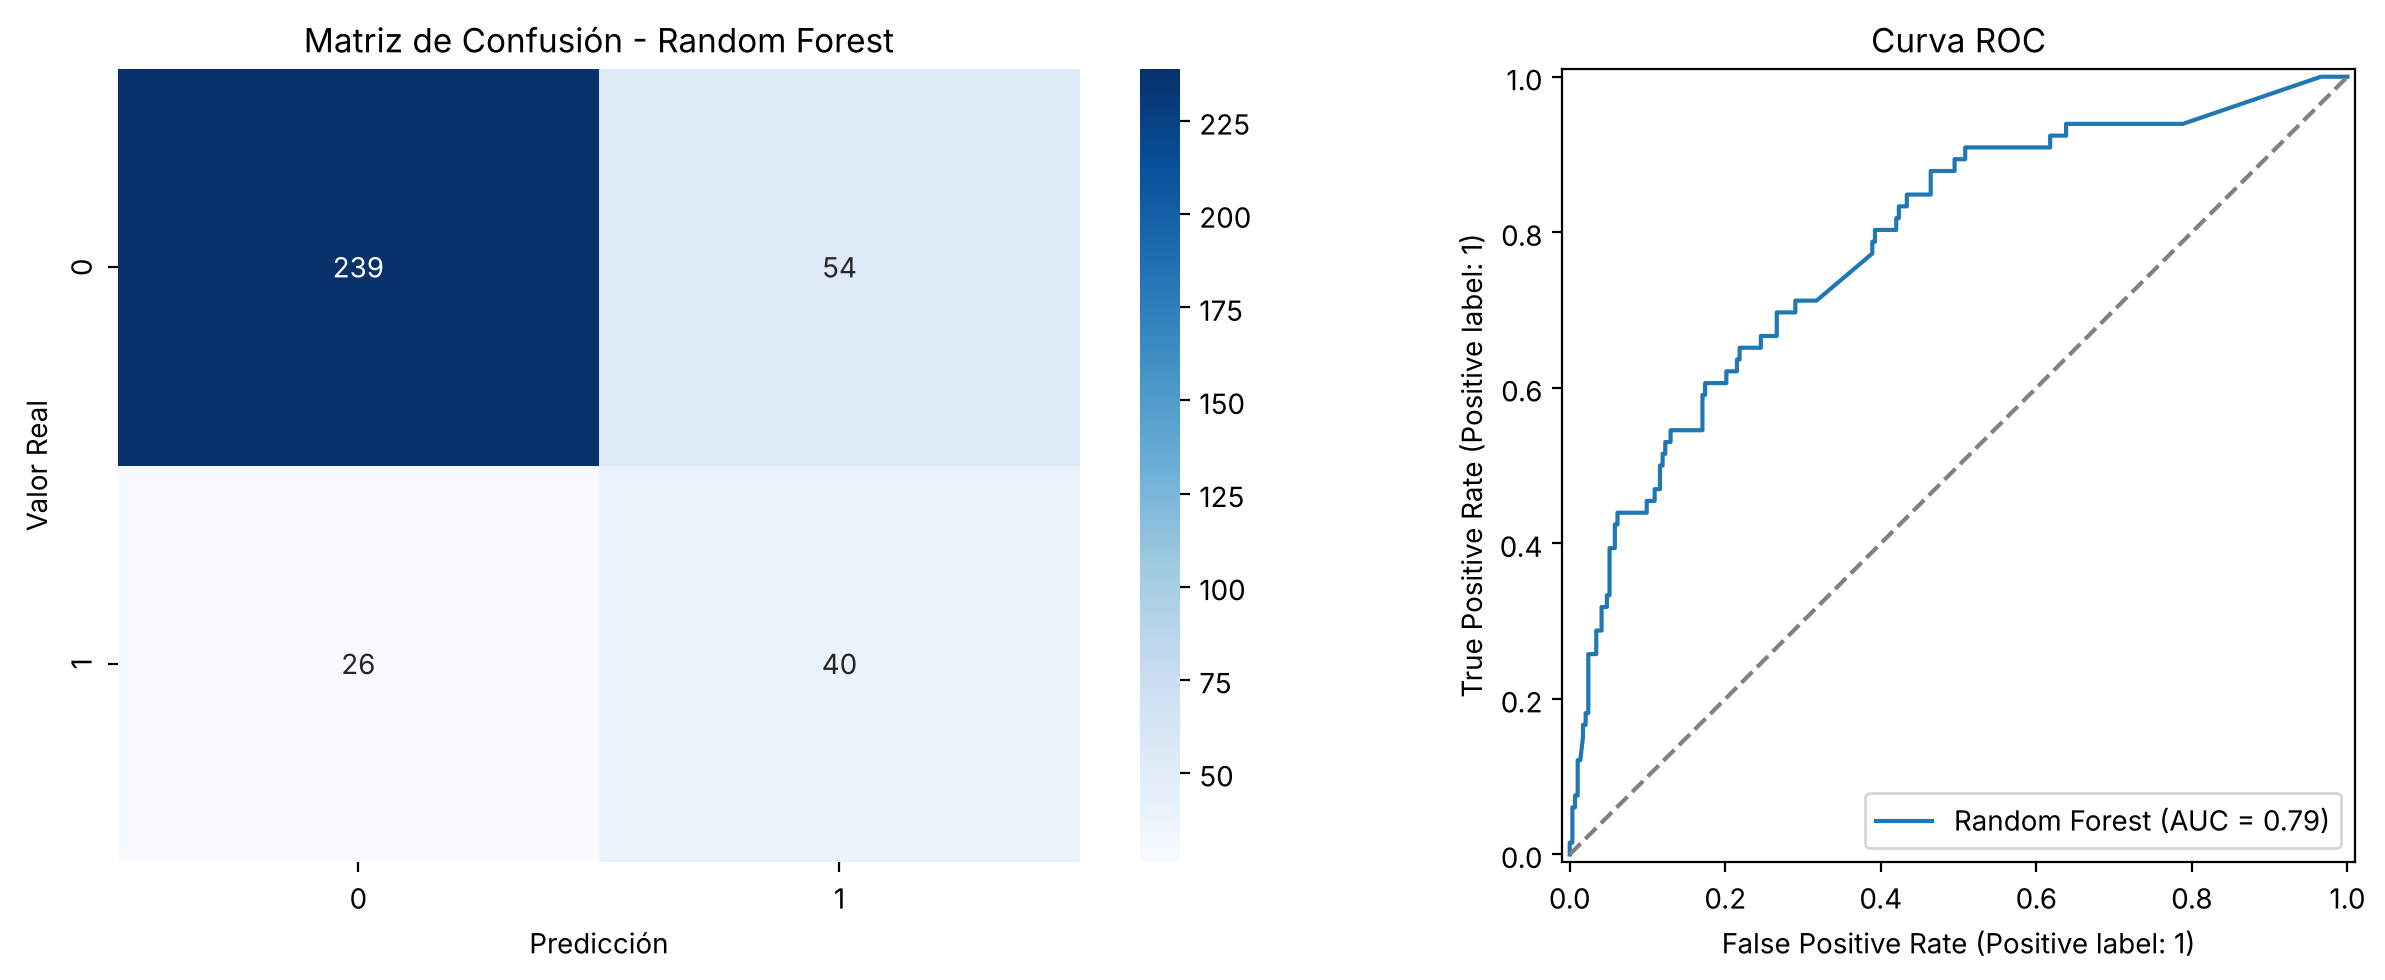

P4_1_1    0.0158
P4_3_1    0.0072
P4_2_1    0.0035
P4_2_2    0.0029
P4_3_3    0.0023
P4_1_2    0.0015
P4_1_8    0.0013
P4_1_4    0.0001
P4_1_5   -0.0004
P4_1_6   -0.0017
P4_1_3   -0.0021
P4_1_7   -0.0025
P4_3_2   -0.0033
dtype: float64


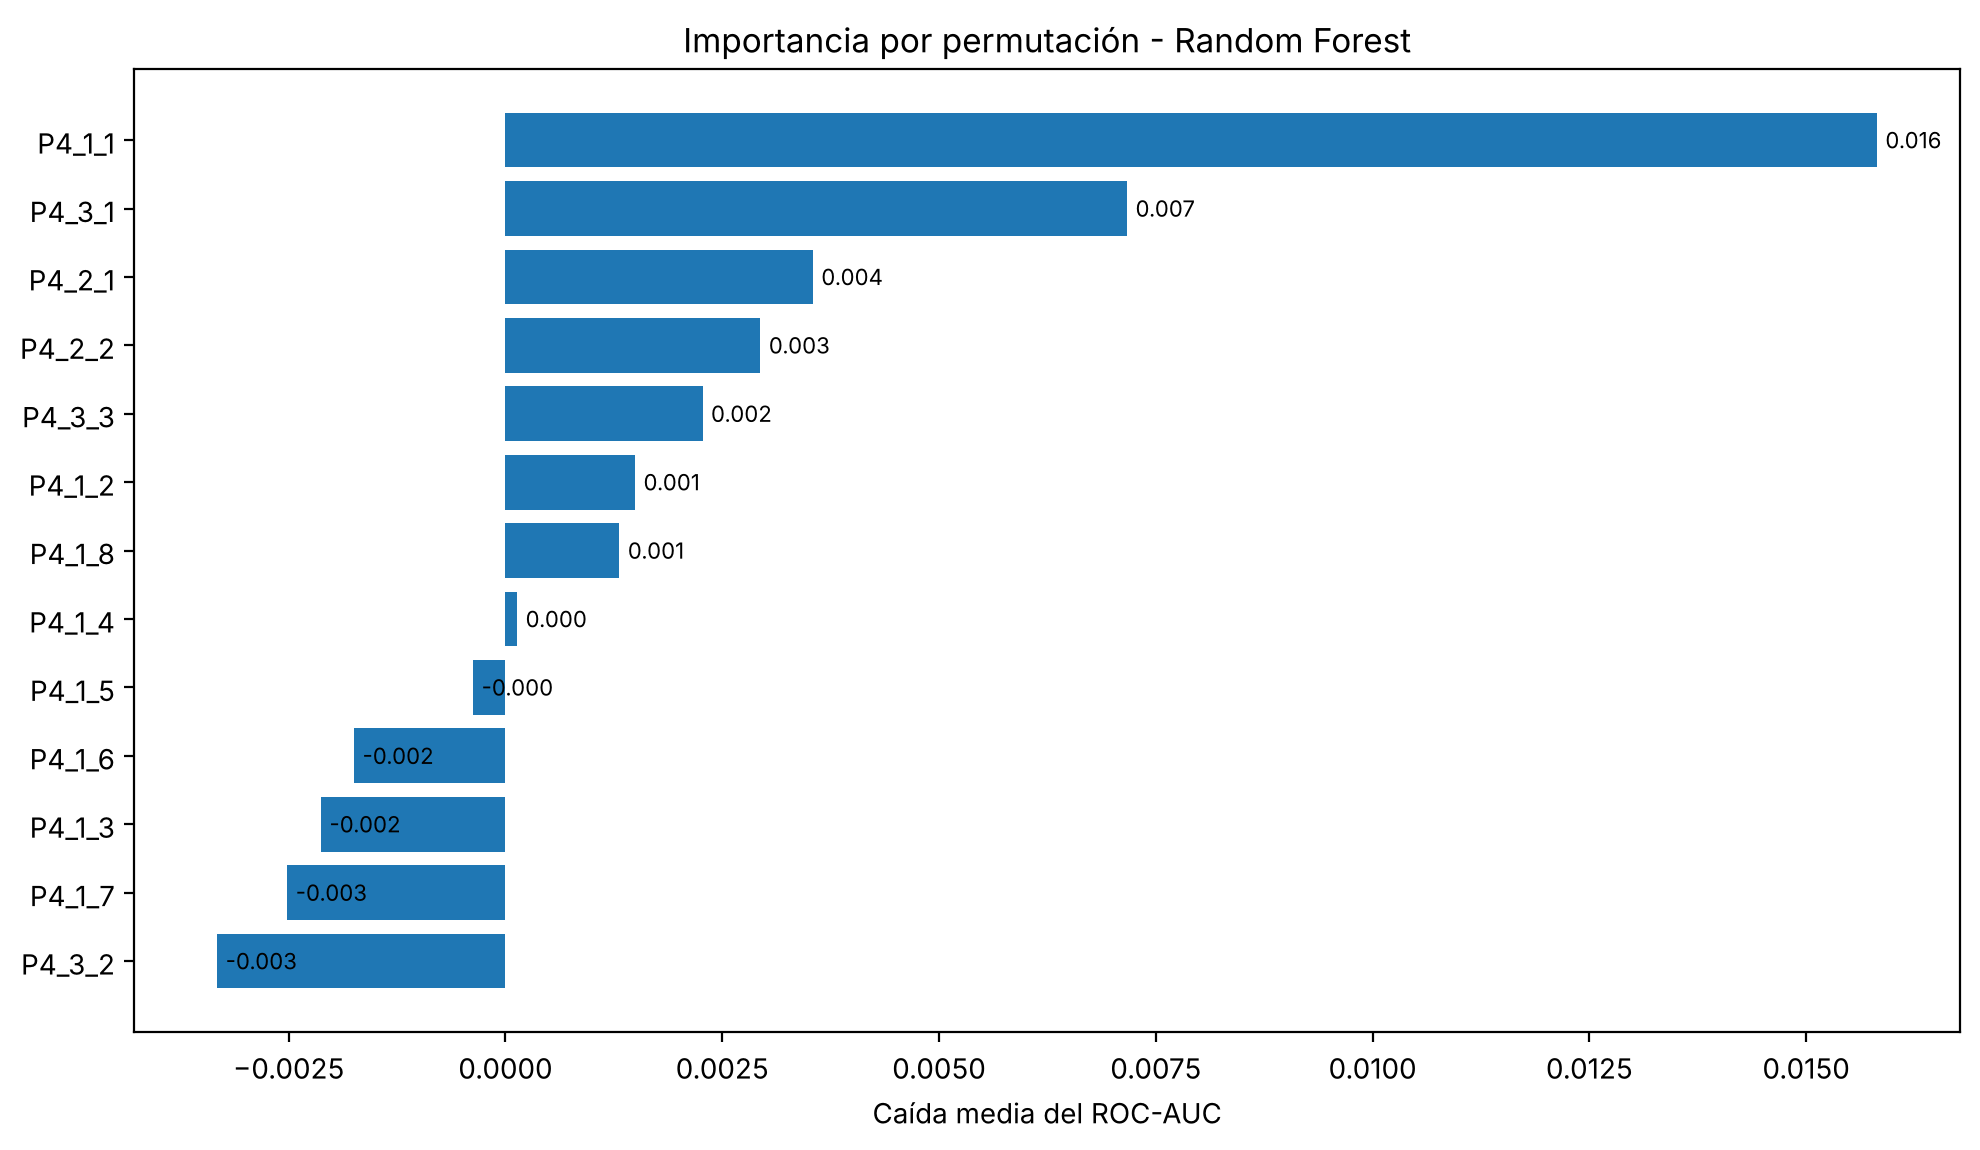

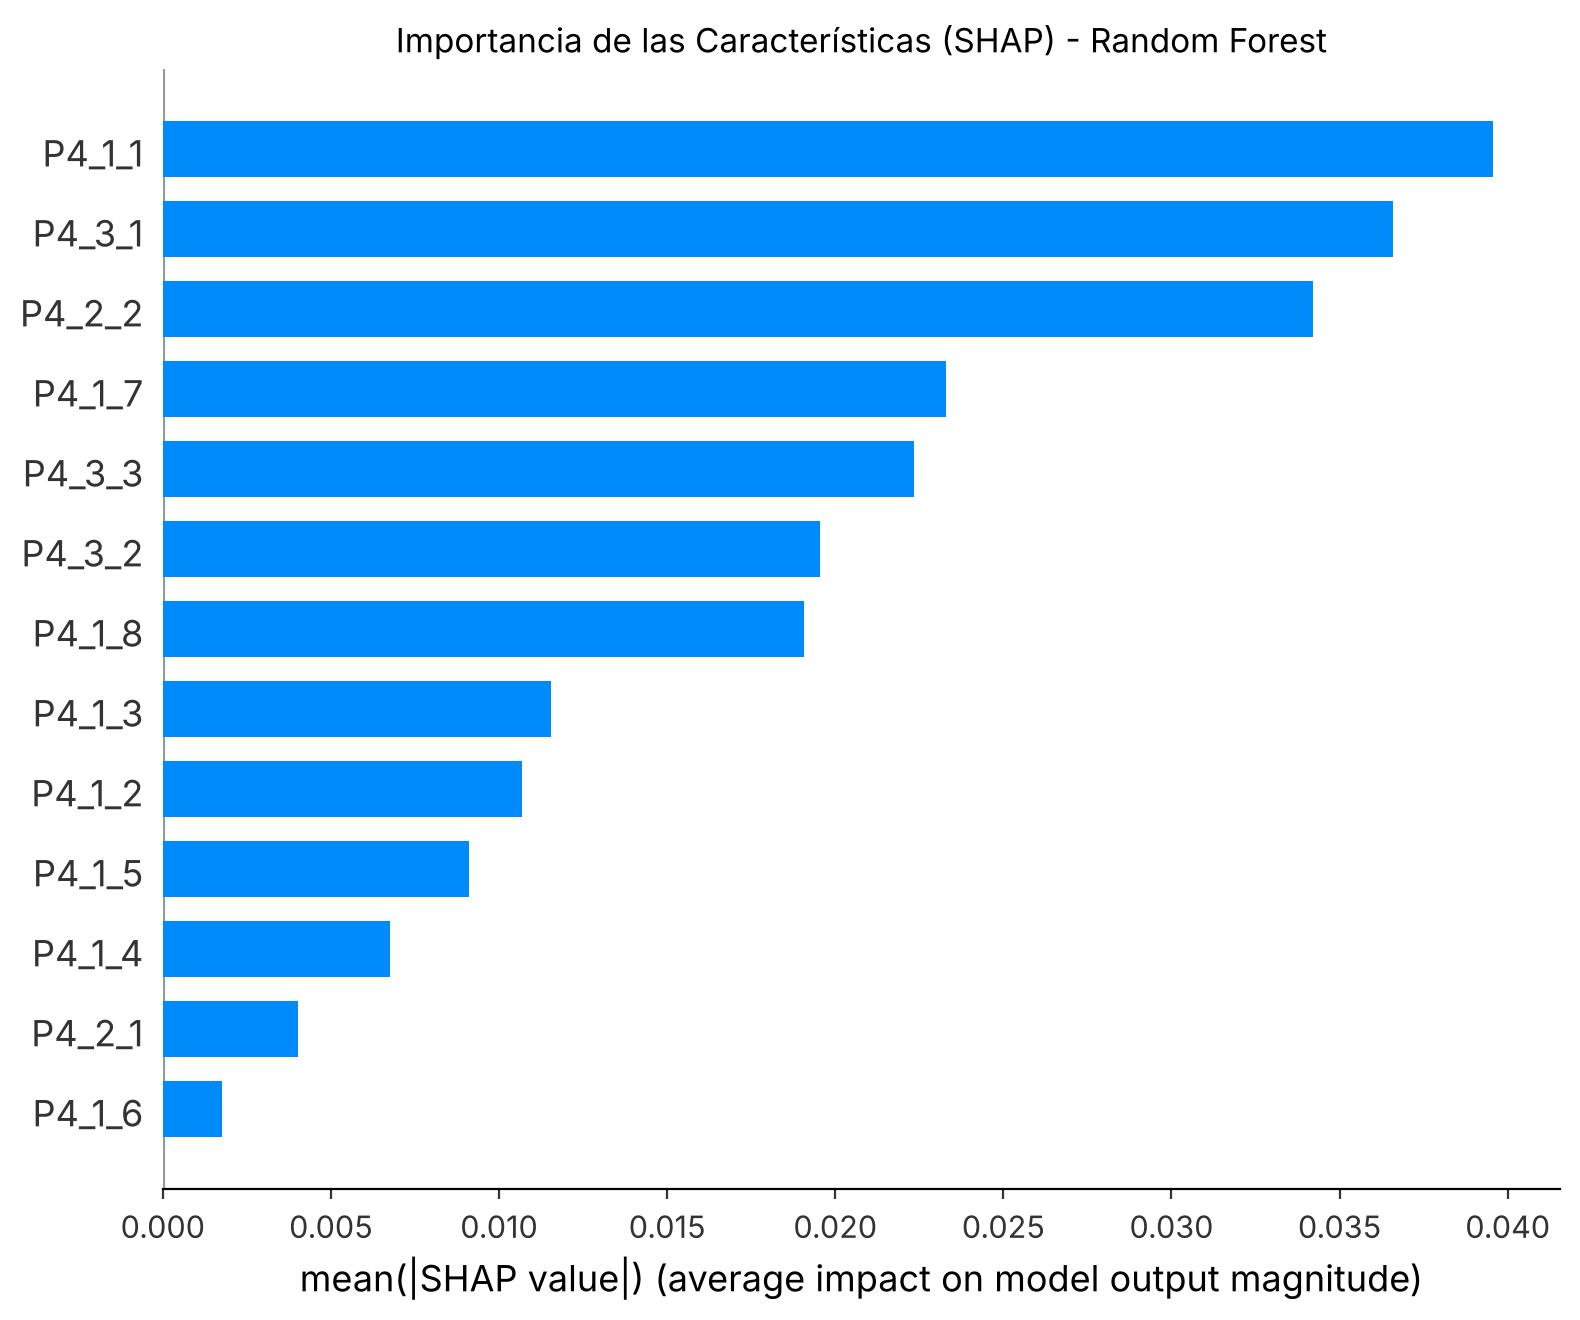

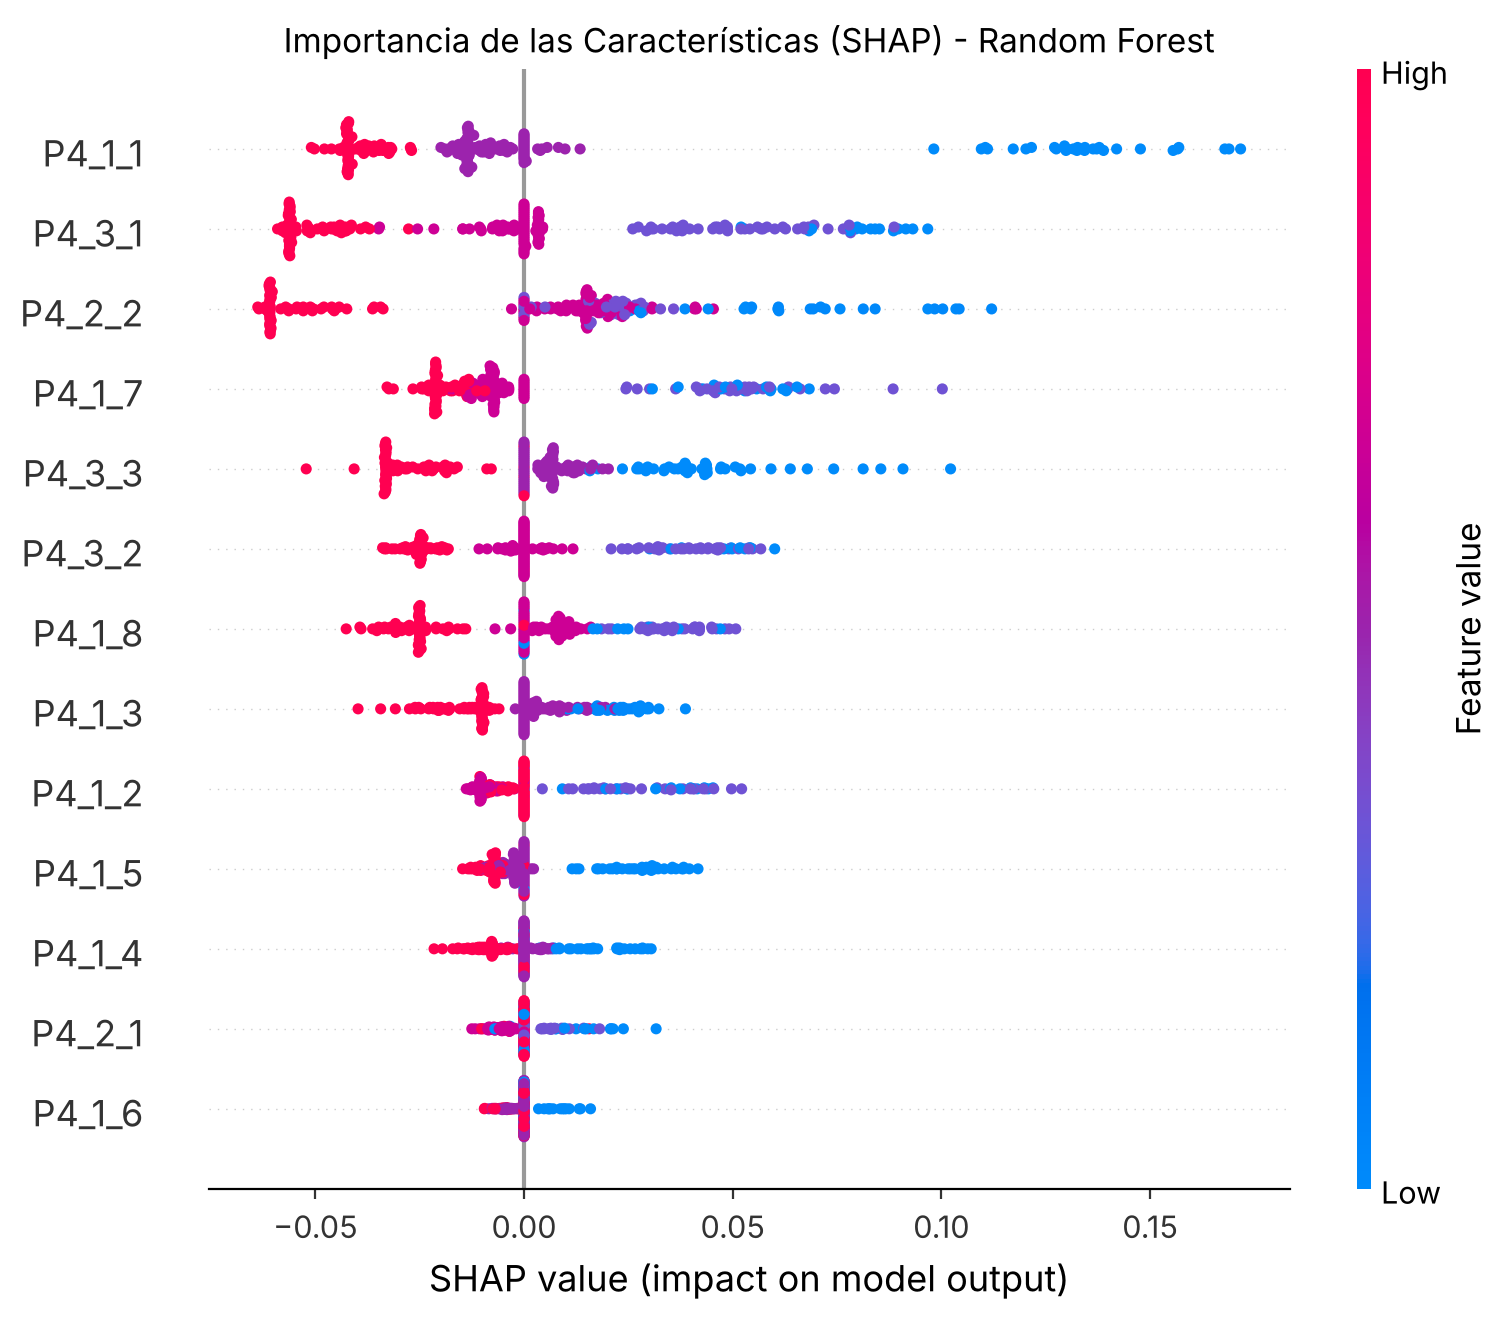

In [9]:
resultados['Satisfacción académica (P4)'] = modelar_bloque(estudiantes_CUSCO, cols_academica,
                                                           'Satisfacción académica (P4)')

# **3. Factores de la Satisfacción con la Imagen y Comunicación de la universidad**
**P26. ¿QUÉ TAN SATISFECHO TE ENCUENTRAS CON CADA UNO DE LOS ASPECTOS DE LA COMUNICACIÓN E IMAGEN DE LA UNIVERSIDAD CONTINENTAL?**

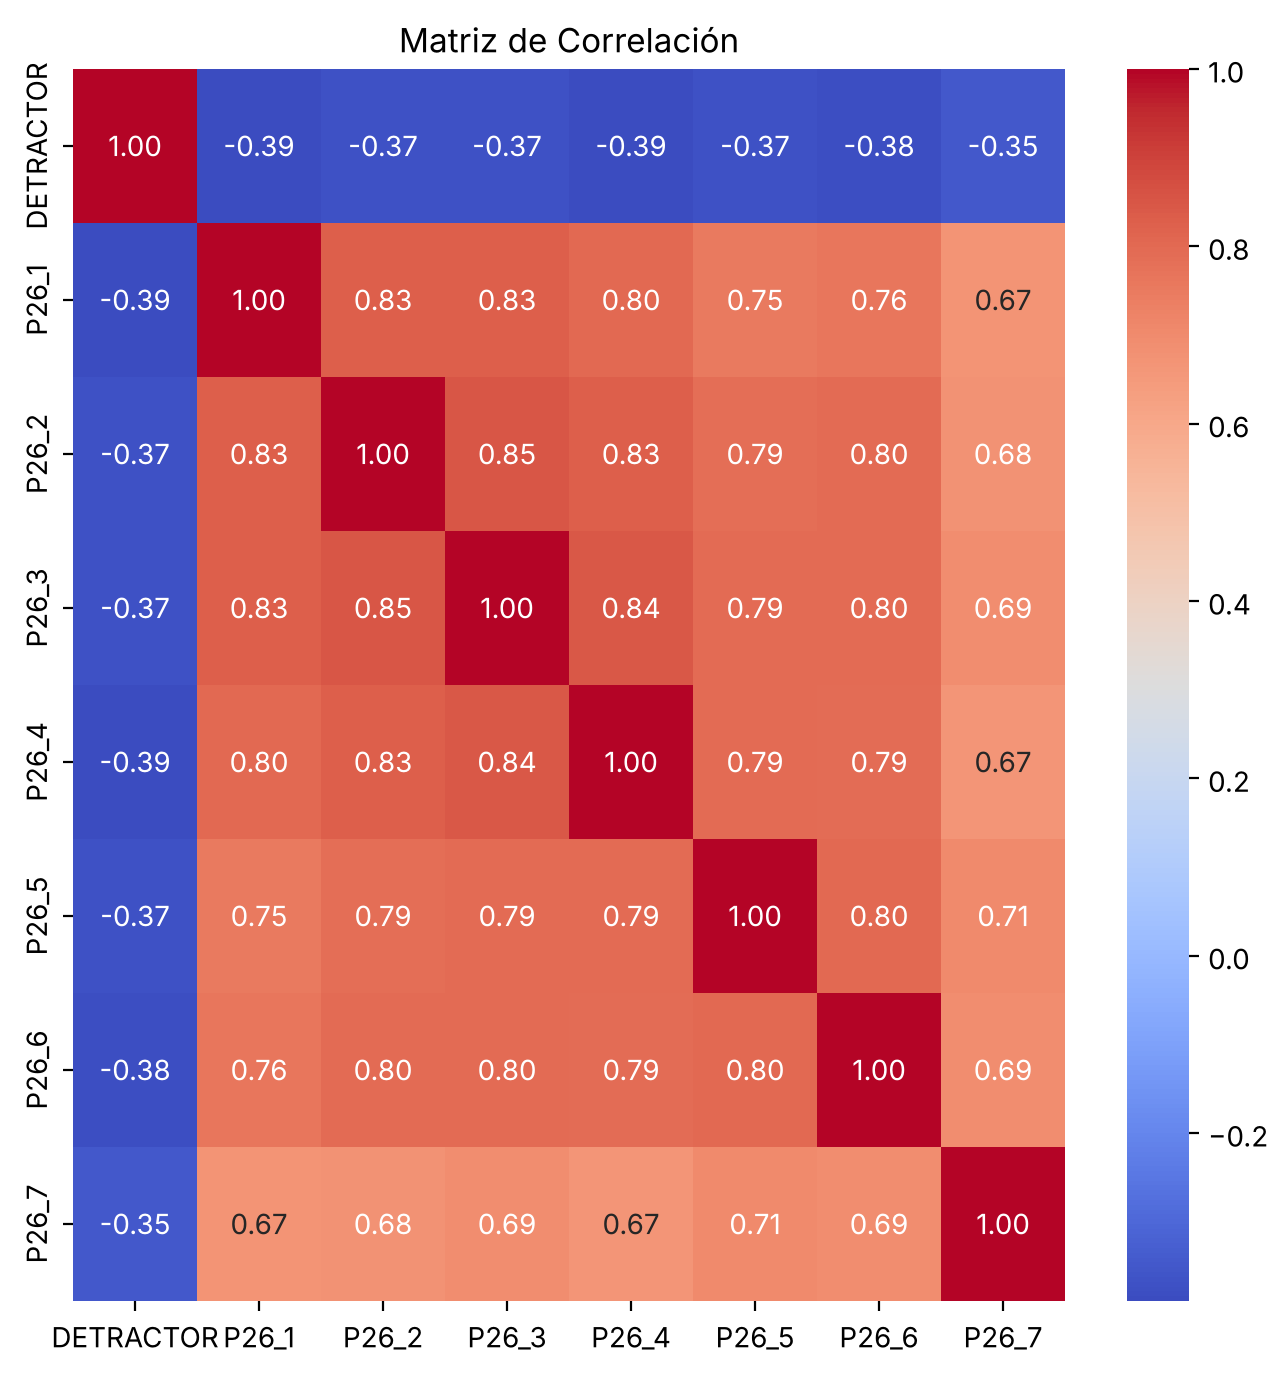

In [10]:
cols_imagen = ['P26_1', 'P26_2', 'P26_3', 'P26_4', 'P26_5', 'P26_6', 'P26_7']
matriz_correlacion(estudiantes_CUSCO, cols_imagen, 8)

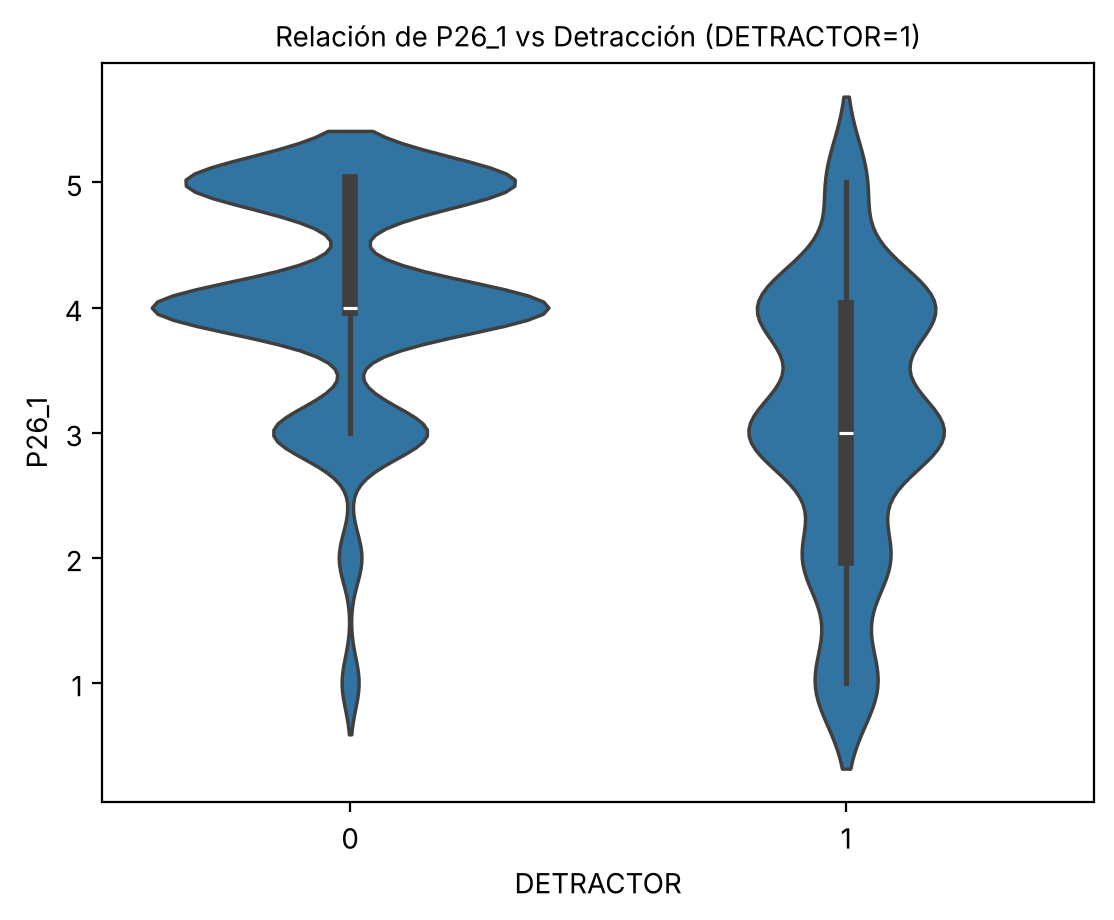

*** Prueba t para P26_1 ***
Estadístico t: -17.76763
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.086867
1    3.084337
Name: P26_1, dtype: float64




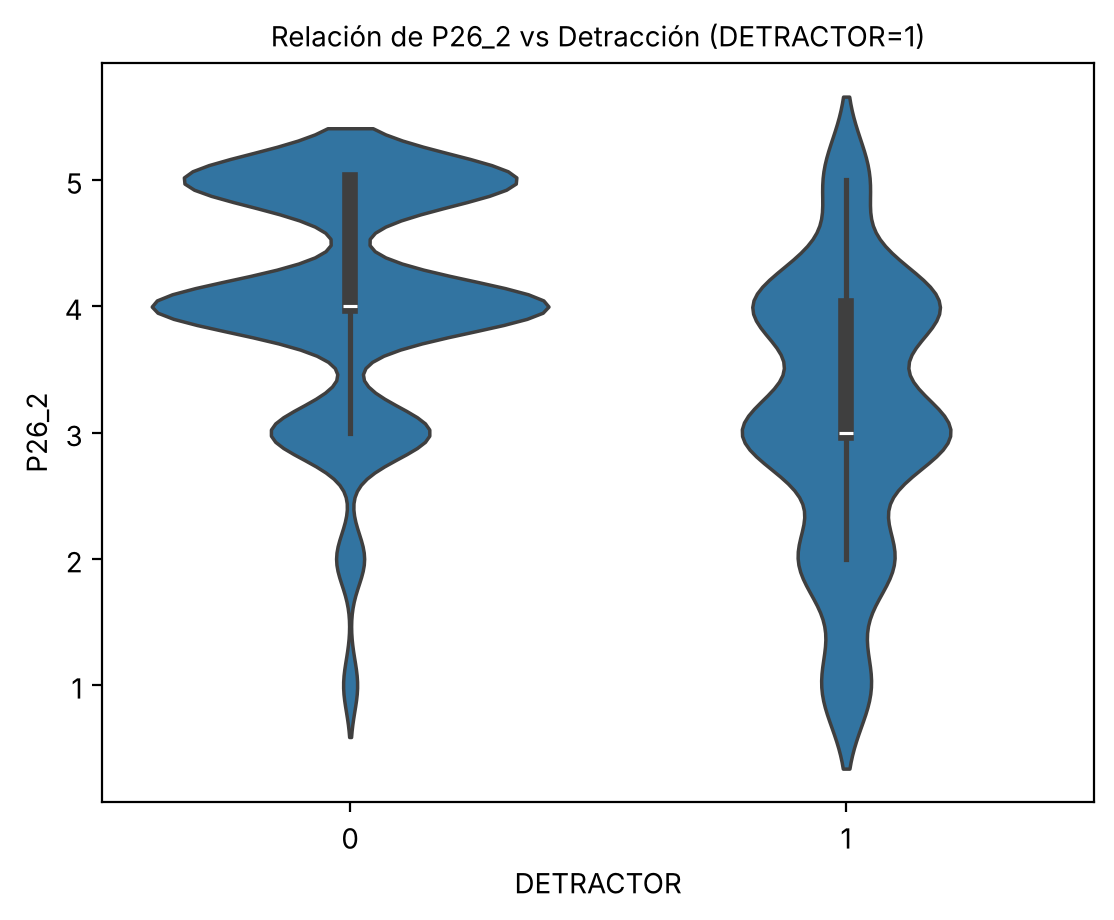

*** Prueba t para P26_2 ***
Estadístico t: -16.81455
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.082079
1    3.144578
Name: P26_2, dtype: float64




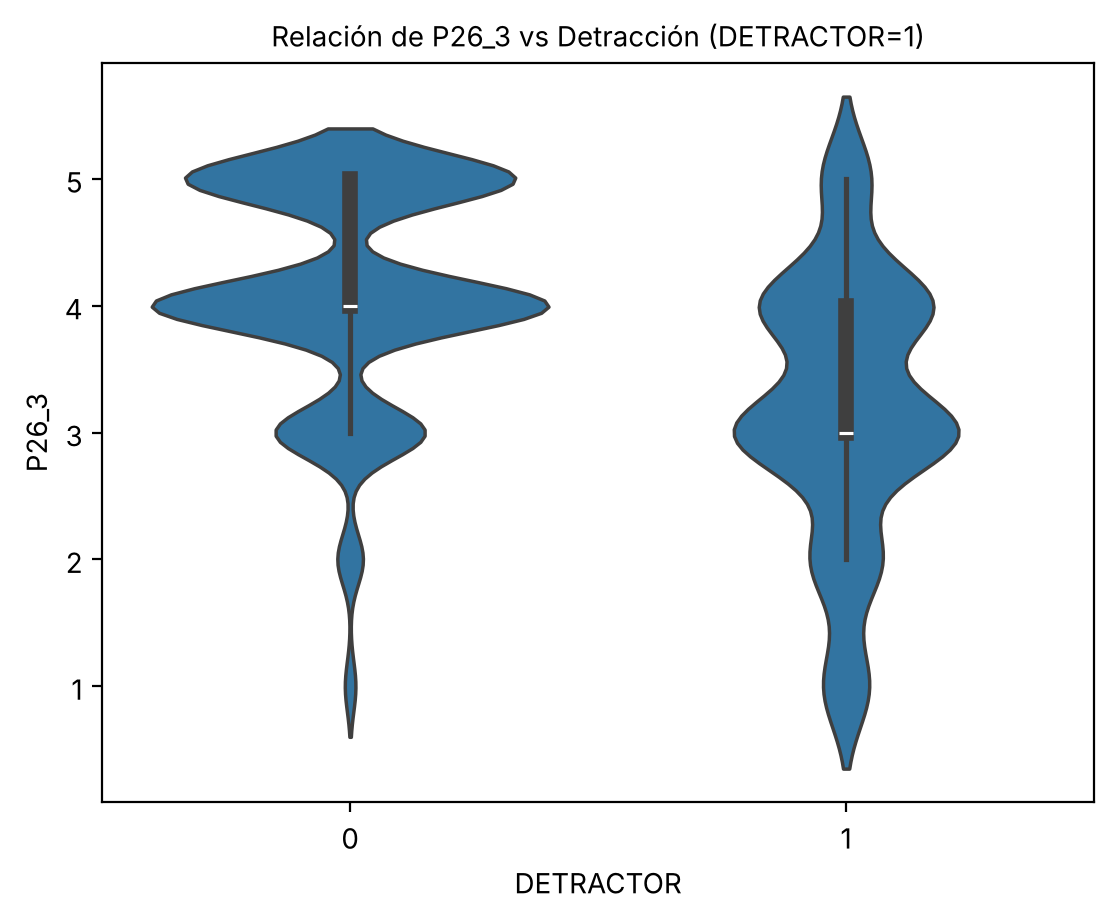

*** Prueba t para P26_3 ***
Estadístico t: -16.85794
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.106703
1    3.192771
Name: P26_3, dtype: float64




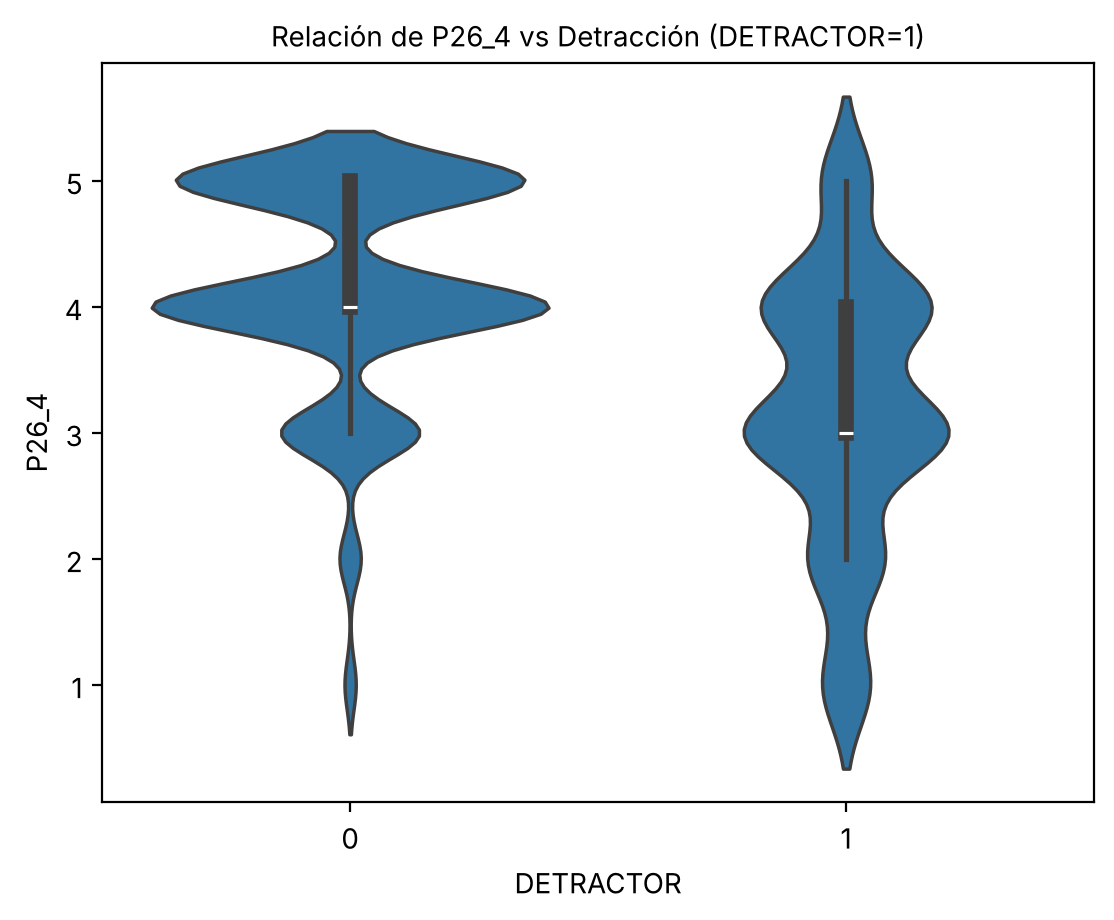

*** Prueba t para P26_4 ***
Estadístico t: -17.89595
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.145691
1    3.177711
Name: P26_4, dtype: float64




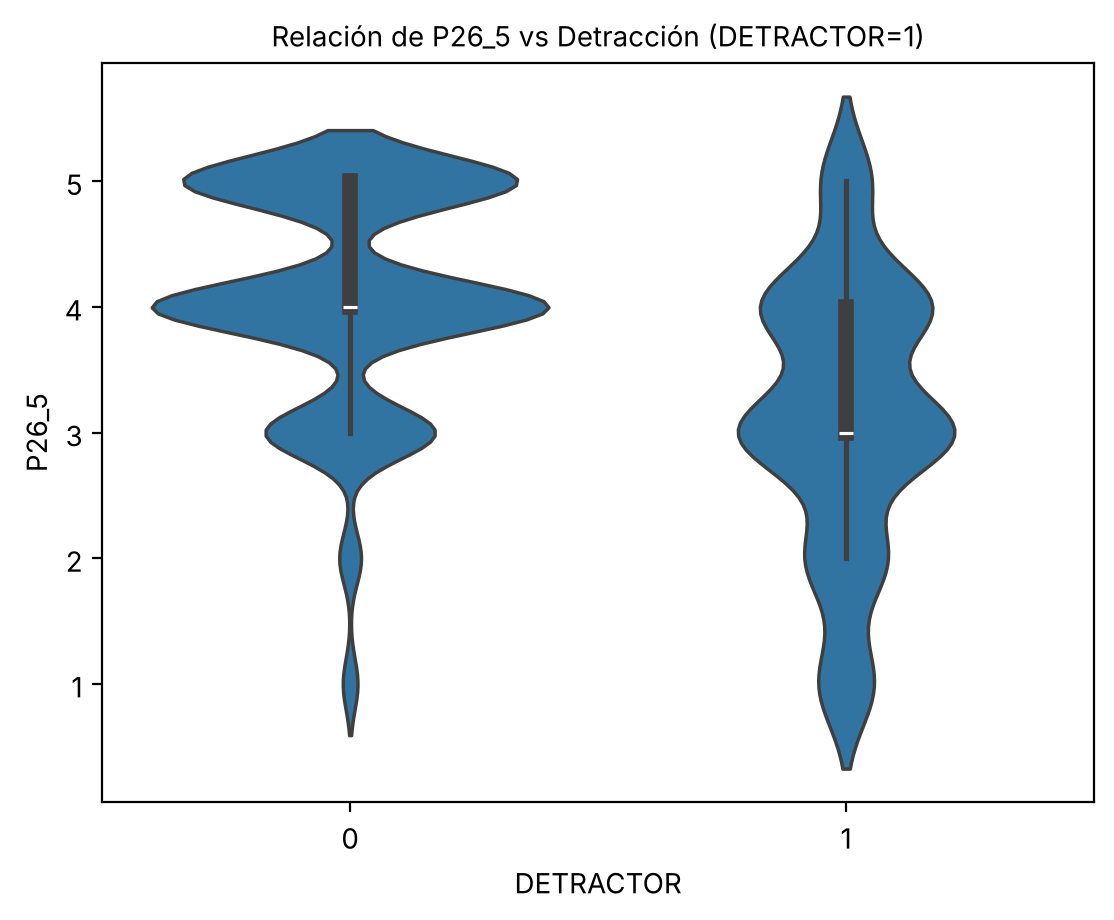

*** Prueba t para P26_5 ***
Estadístico t: -16.94191
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.082079
1    3.138554
Name: P26_5, dtype: float64




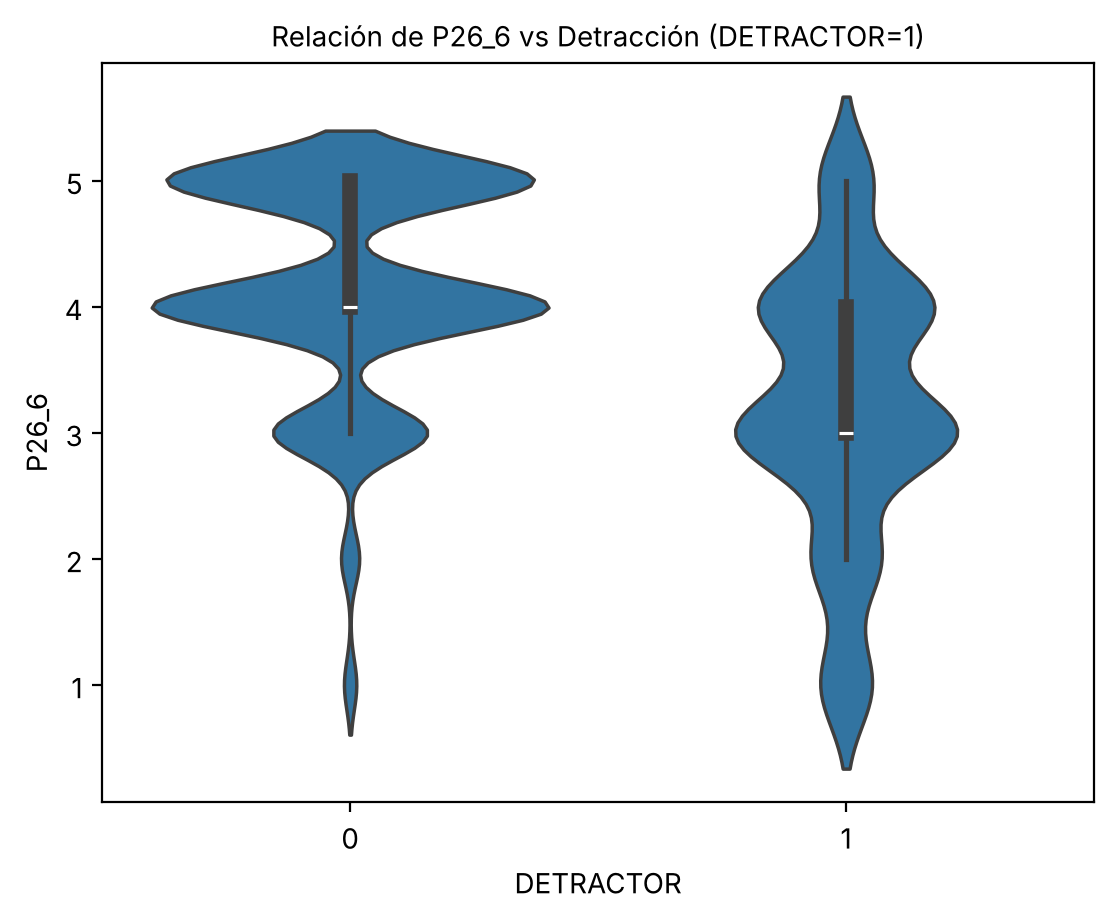

*** Prueba t para P26_6 ***


Estadístico t: -17.57749
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.147059
1    3.192771
Name: P26_6, dtype: float64




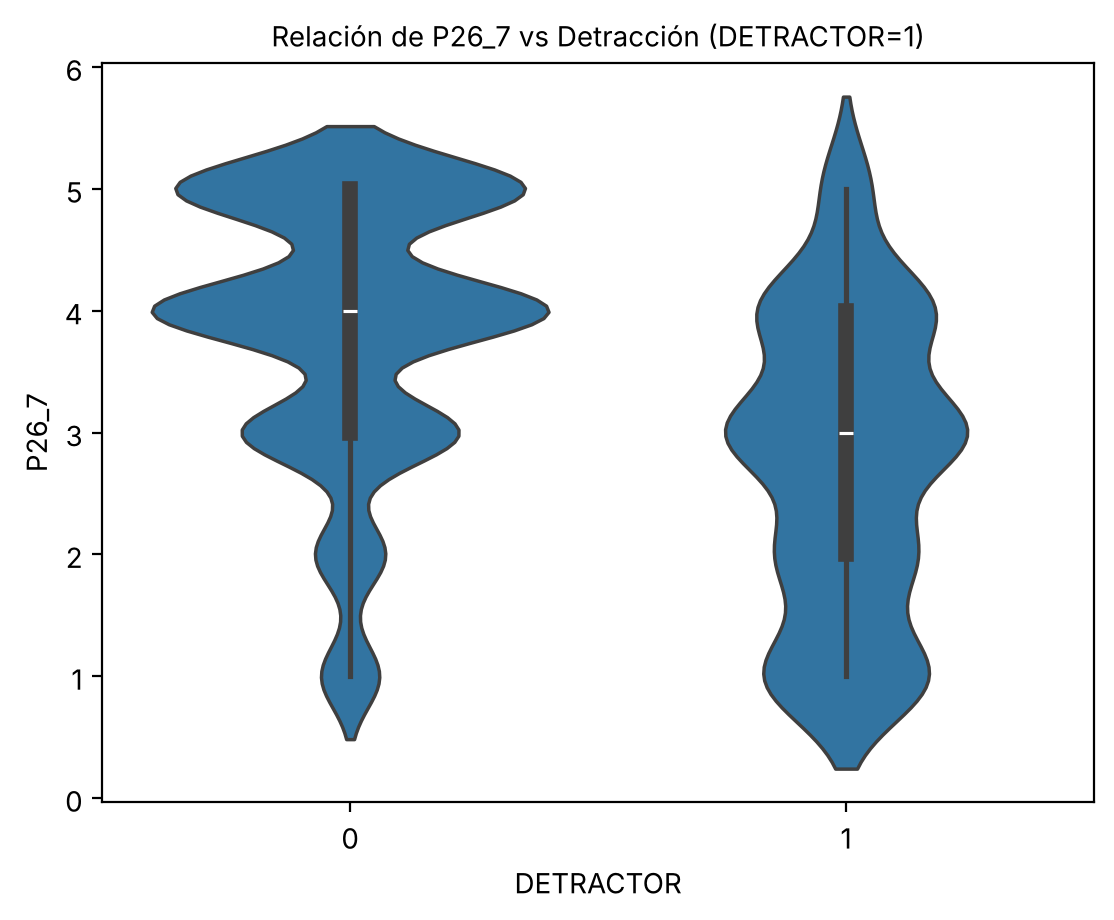

*** Prueba t para P26_7 ***
Estadístico t: -15.86819
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    3.832421
1    2.743976
Name: P26_7, dtype: float64


[Comunicación e imagen (P26)] Variables que pasan la prueba t: ['P26_1', 'P26_2', 'P26_3', 'P26_4', 'P26_5', 'P26_6', 'P26_7']


                     ROC-AUC  Recall detractor  F1 detractor  Accuracy
Modelo                                                                
Regresión Logística    0.790             0.700         0.501     0.742
Random Forest          0.783             0.647         0.480     0.740
Gradient Boosting      0.768             0.639         0.466     0.729
Modelo elegido: Regresión Logística
Accuracy en prueba: 0.766
ROC-AUC en prueba: 0.785
Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.91      0.79      0.85       293
           1       0.42      0.67      0.51        66

    accuracy                           0.77       359
   macro avg       0.66      0.73      0.68       359
weighted avg       0.82      0.77      0.78       359



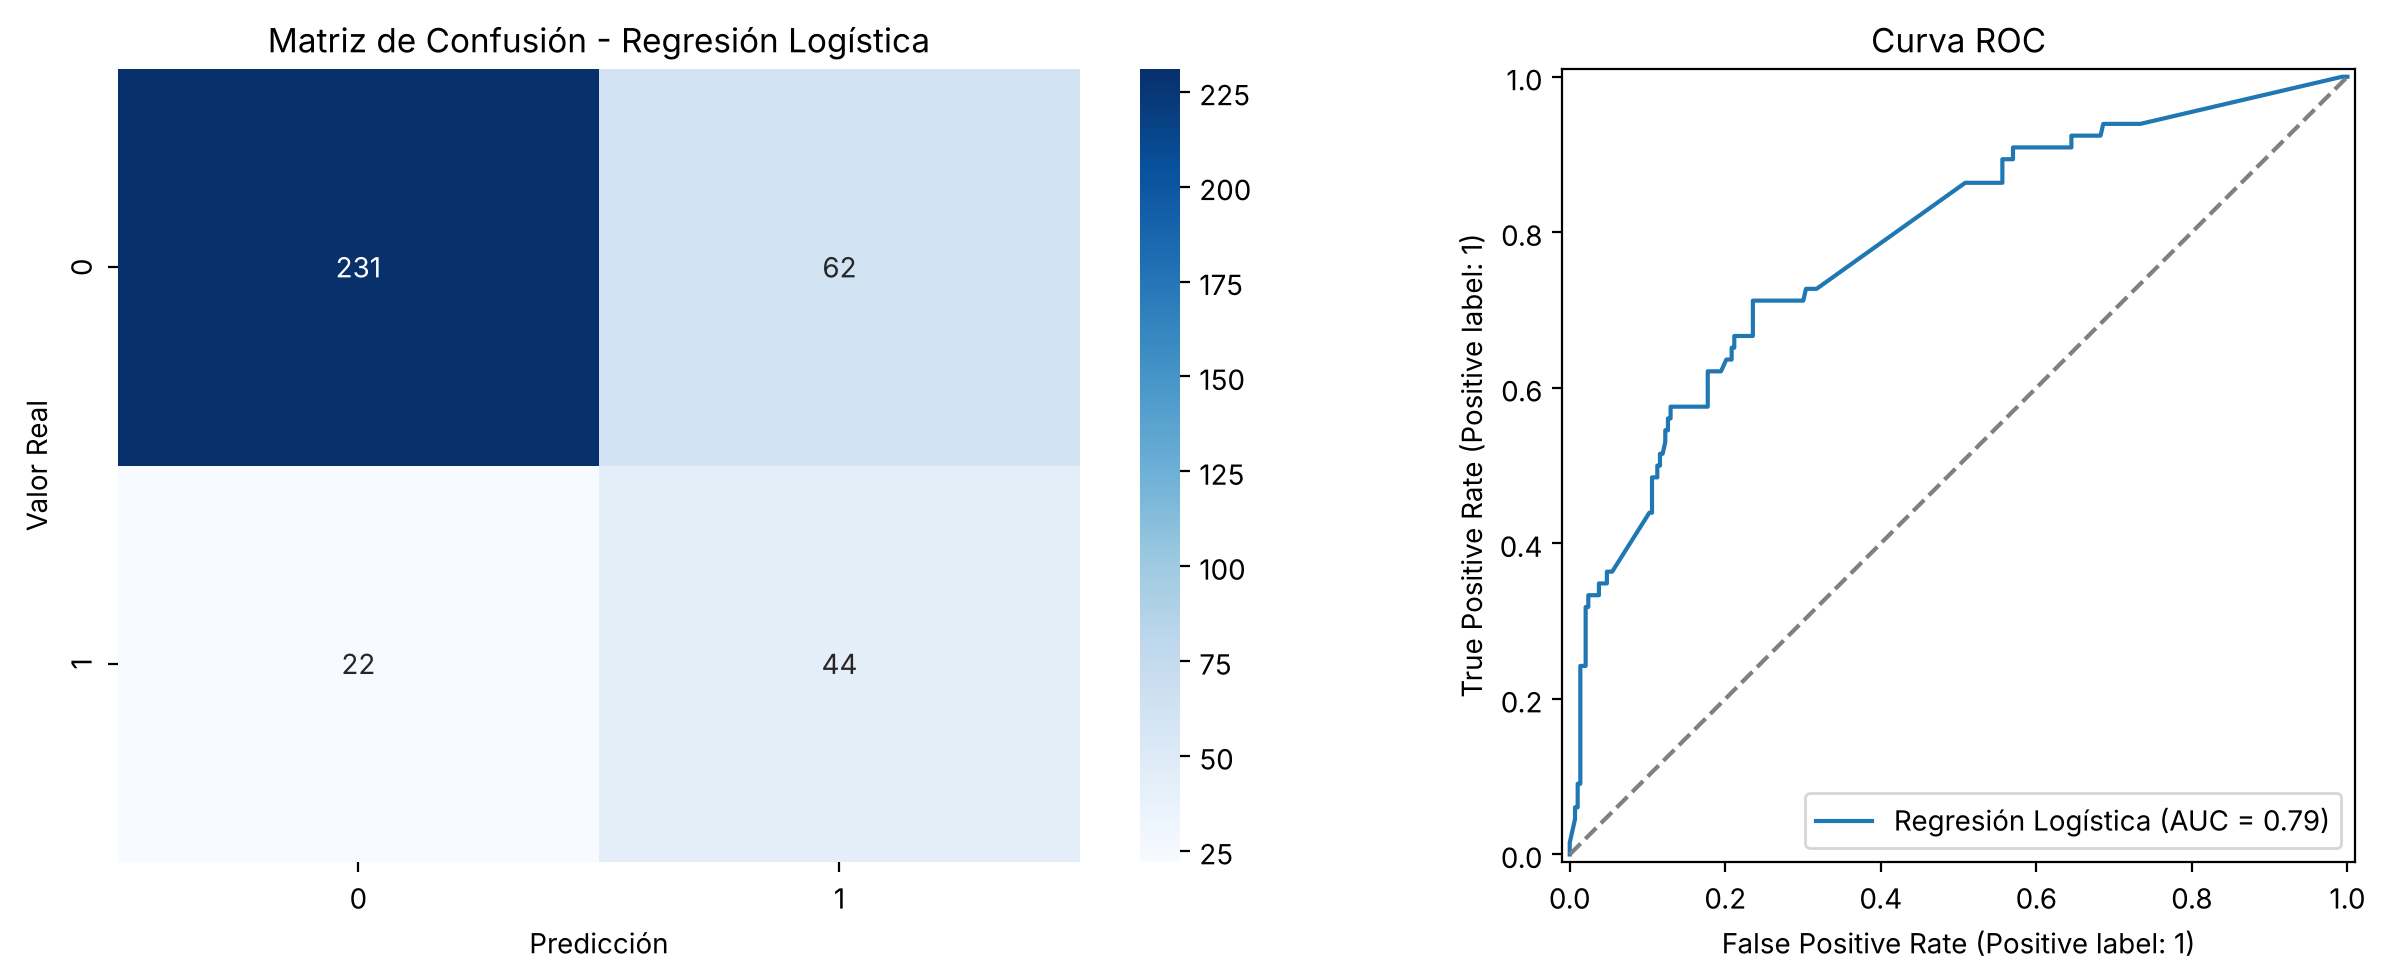

P26_6    0.0122
P26_4    0.0113
P26_7    0.0101
P26_1    0.0094
P26_2    0.0022
P26_5    0.0007
P26_3   -0.0023
dtype: float64


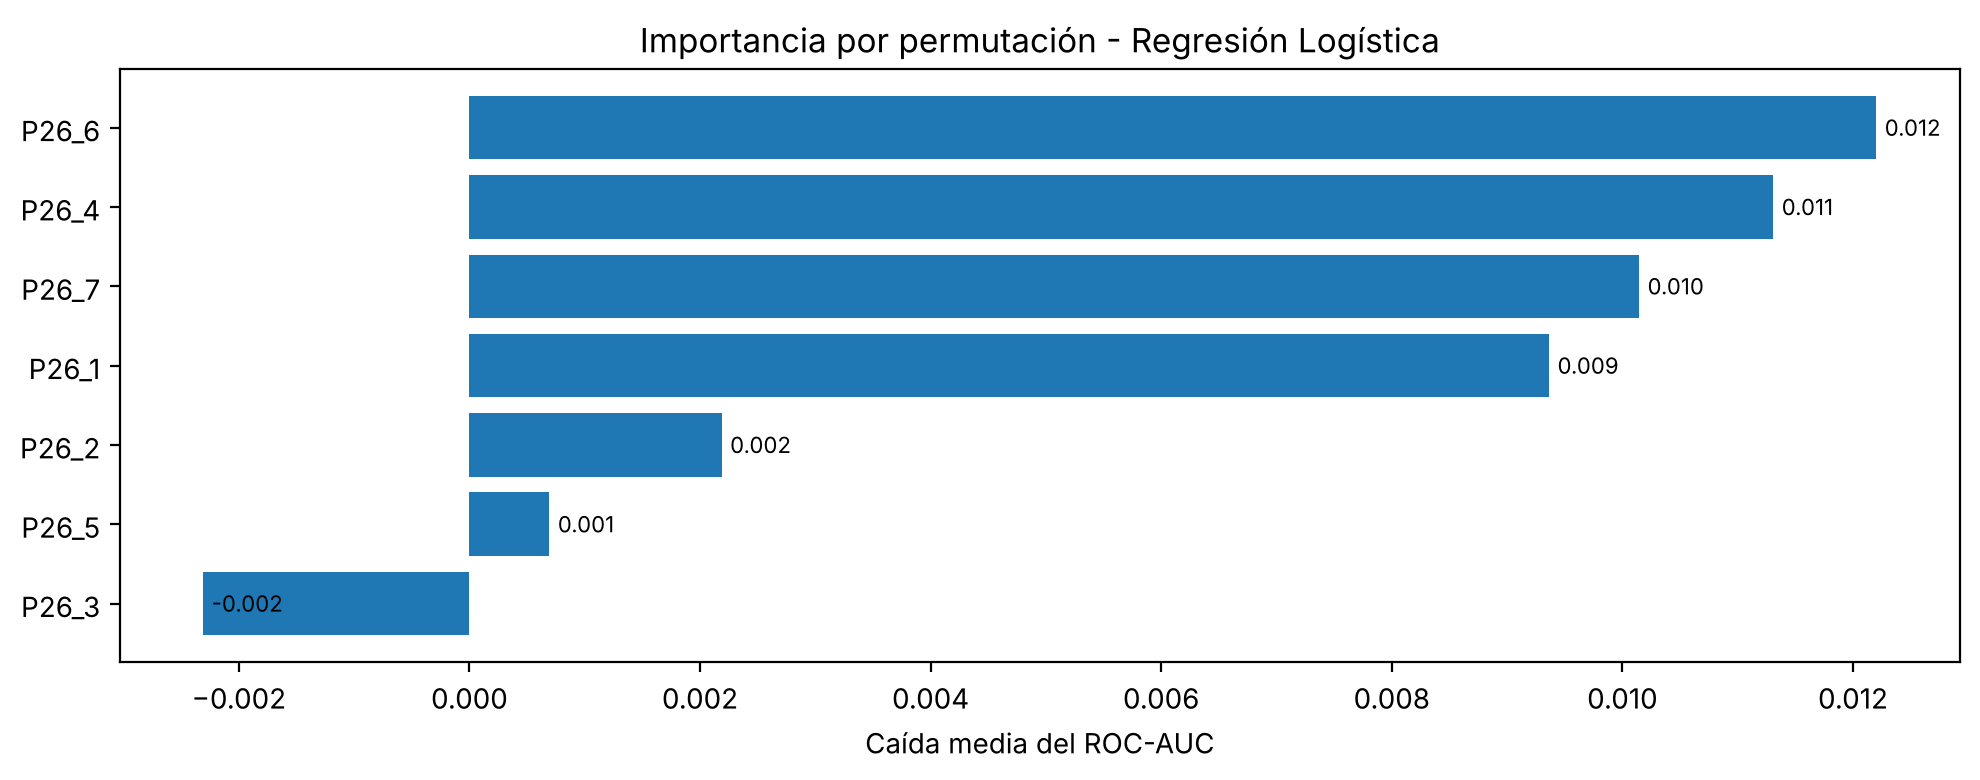

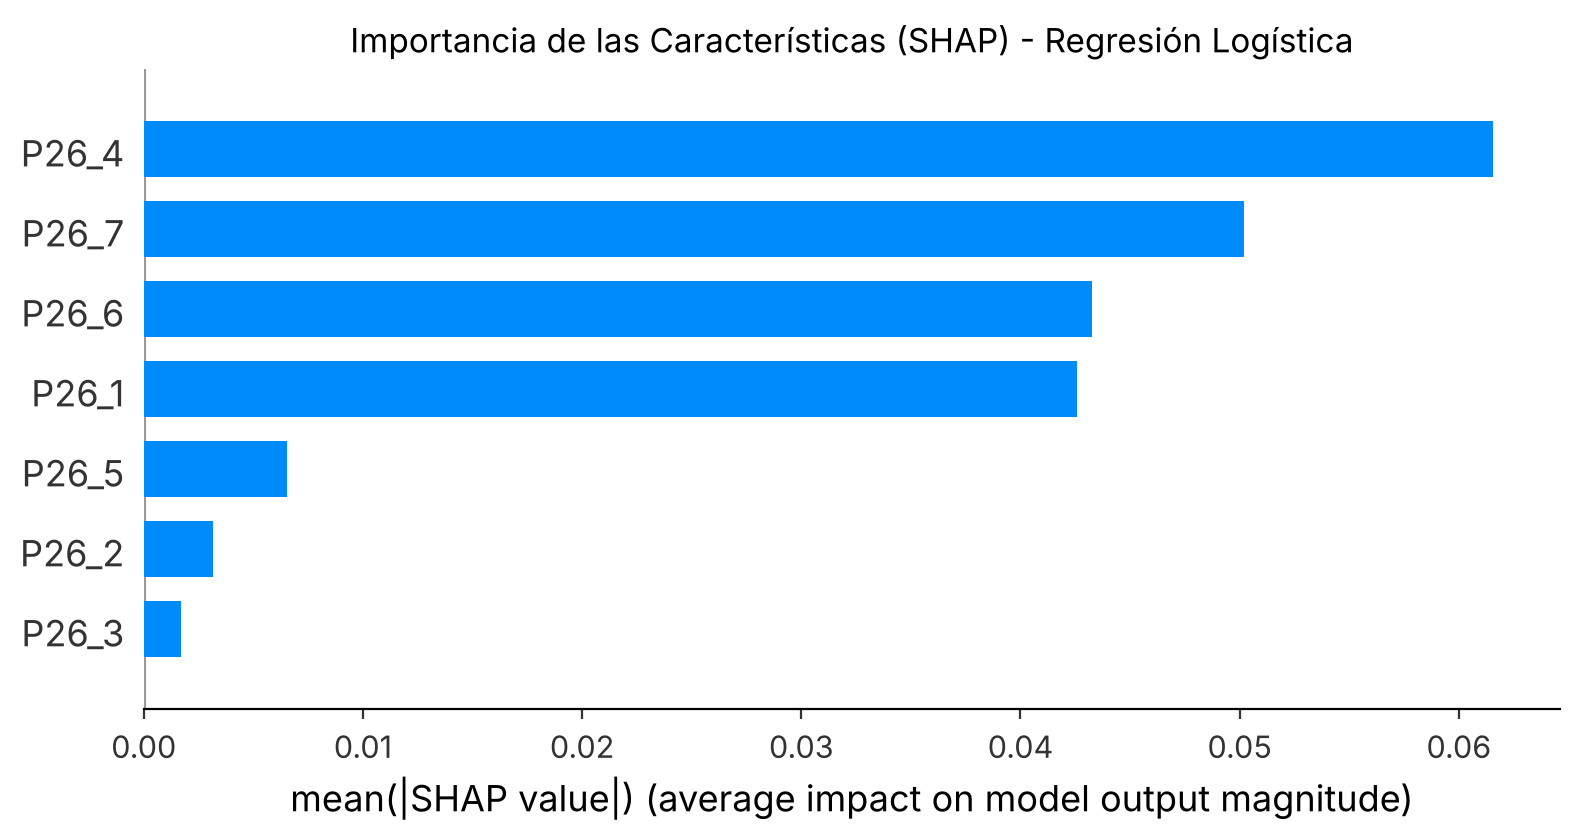

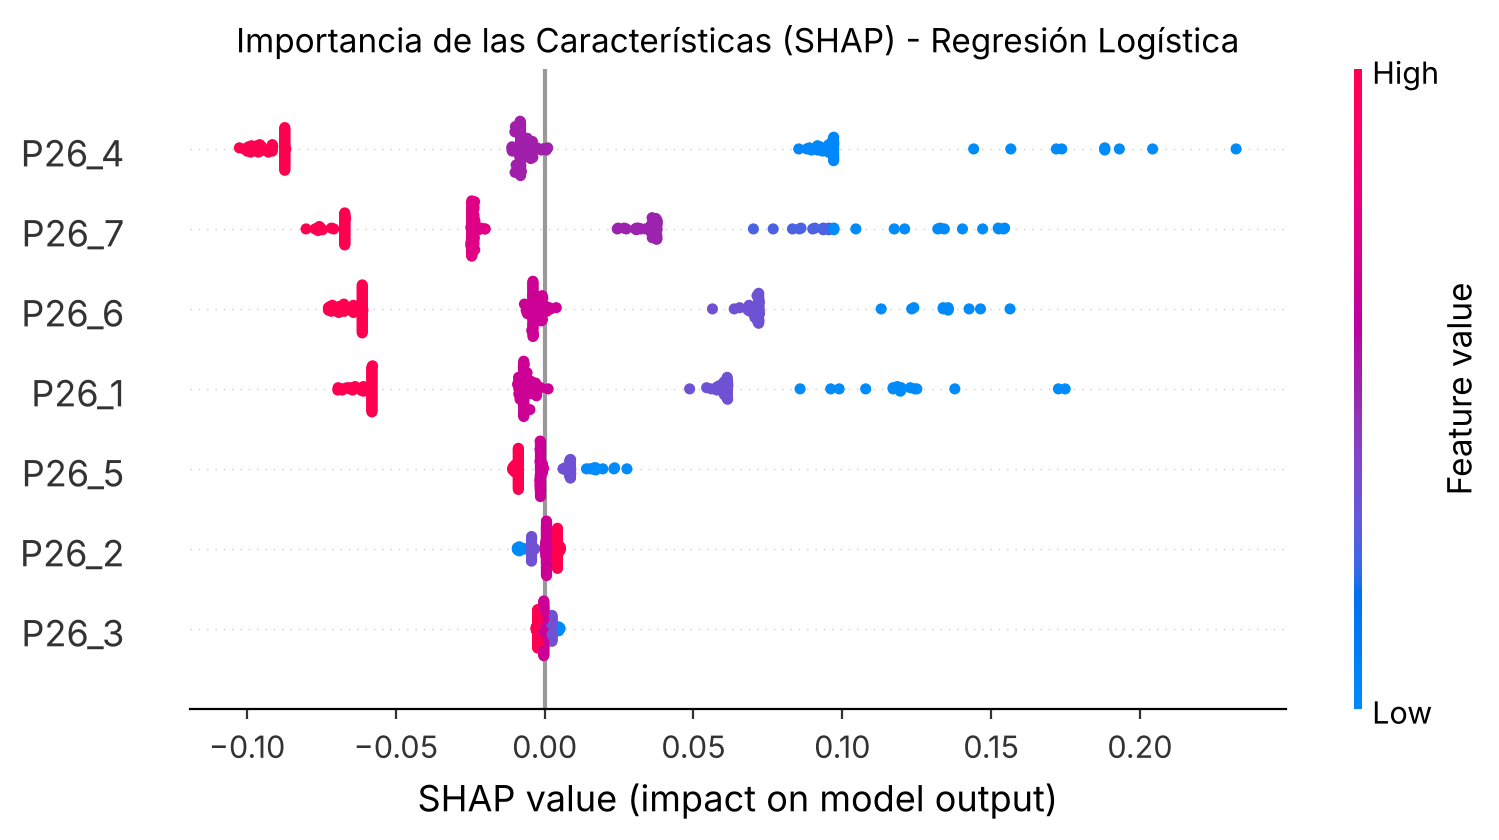

In [11]:
resultados['Comunicación e imagen (P26)'] = modelar_bloque(estudiantes_CUSCO, cols_imagen,
                                                           'Comunicación e imagen (P26)')

# **Resumen de resultados**

Mejor modelo de cada bloque (según ROC-AUC en validación cruzada) y los 3 factores con mayor
importancia por permutación.

In [12]:
resumen = pd.DataFrame([
    {'Bloque': bloque,
     'Mejor modelo': r['modelo'],
     'ROC-AUC (CV)': round(r['tabla'].loc[r['modelo'], 'ROC-AUC'], 3),
     'Recall detractor (CV)': round(r['tabla'].loc[r['modelo'], 'Recall detractor'], 3),
     'Top 3 factores': ', '.join(r['importancias'].index[:3])}
    for bloque, r in resultados.items()
]).set_index('Bloque')
print(resumen.to_string())

                                    Mejor modelo  ROC-AUC (CV)  Recall detractor (CV)                            Top 3 factores
Bloque                                                                                                                         
Satisfacción general         Regresión Logística         0.851                  0.763  SATIF_ACAD, SATISF_CAMP_VIRT, SATISF_EXP
Satisfacción académica (P4)        Random Forest         0.812                  0.650                    P4_1_1, P4_3_1, P4_2_1
Comunicación e imagen (P26)  Regresión Logística         0.790                  0.700                       P26_6, P26_4, P26_7
